# Klasifikasi Kesegaran Daun Tanaman Kampus (Topik 2) — Modul Feature Extraction & ML Klasik (v2)
**Mata Kuliah:** Pengolahan Citra Digital dan Visi Komputer (CIF61339) - Kelas A  
**Dosen Pengampu:** Yuita Arum Sari, S.Kom., M.Kom., Ph.D.  
**Fakultas Ilmu Komputer (FILKOM), Universitas Brawijaya**

**Penanggung Jawab Modul:**  
2. **Nadhif Adita Fernanda (235150201111033)** - *Mahasiswa 2: Feature & ML Klasik*

---
### 🎯 Tujuan & Cakupan Notebook (`v2` — Sinkron `Dataset_P2_Processed_v2`)
Notebook ini mengonsumsi langsung **619 citra PNG *lossless*** dan indeks partisi `dataset_master_p2.csv` (`v2`) yang dihasilkan modul Mahasiswa 1 (`02_PCD_Augmentation_and_Split_P2.ipynb`), yang telah memperbaiki *resize* aspek rasio (`resize_long(800)` + `letterbox(224)`), gamma adaptif (`L**gamma` menuju `TARGET_L = 0,716`), serta augmentasi seragam *sebelum crop* ROI tanpa menggeser Hue/Saturation:
1. **Ekstraksi 28 Fitur Handcrafted (`A0`, `C1`, `A`):** **12 Fitur Warna** (*Mean* & *Std* $H, S, V, L^*, a^*, b^*$), **6 Fitur Tekstur Spasial GLCM**, dan **10 Fitur $LBP^{riu2}$**.
2. **Evaluasi Baseline ML Klasik (5-Fold CV Bebas Leakage):** Komparasi **A0 vs A**, **Dampak Augmentasi**, dan **Ablasi Fitur (Warna vs Tekstur vs Fusi)**.
3. **Diagnosis Confusion Matrix & Error Analysis:** Matriks konfusi $3 \times 3$ pada 127 foto asli + inspeksi galat.
4. **Uji Lintas Sesi & Signifikansi (LOSO E1/E8, CV Berulang E2, McNemar E3, Paired Ablation E4, Augmentasi LOSO E9):** Memisahkan efek PCD vs *masking* ROI lintas sesi pengambilan foto.
5. **Hyperparameter Tuning Anti-Leakage (*Nested 5-Fold CV*):** `StratifiedGroupKFold(groups=parent_id)` untuk SVM, Random Forest, dan KNN (Fusi 28 fitur & perbandingan Warna-saja 12 fitur) + evaluasi LOSO pasca-tuning.
6. **Ekspor Model (`.pkl`) & Pipeline `predict` End-to-End (`v2`):** Menyimpan `oof_fold_models_A.pkl` dan `final_best_ml_model.pkl` beserta fungsi pra-pemrosesan foto baru yang identik dengan pipeline `v2`.
7. **Benchmark Waktu Latih, Latensi (`ms/citra`), & Galeri Benar vs Salah (`v2`):** Mengukur waktu latih model, latensi inferensi end-to-end per citra (PCD + 28 fitur + *predict*), serta memvisualisasikan contoh prediksi benar dan salah dari model OOF *tuned*.

## 0. Setup Google Drive & Muat `dataset_master_p2.csv` (Versi `v2`)
**Tujuan:** Menghubungkan Google Drive dan memuat indeks `dataset_master_p2.csv` dari folder **`Dataset_P2_Processed_v2`** (memastikan versi `v2` yang terbaca melalui kolom `gamma_used` dan ekstensi `.png`).

In [2]:
import os
import pandas as pd
from google.colab import drive

drive.mount('/content/drive')

OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2'
csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')

if not os.path.exists(csv_master_path):
    raise FileNotFoundError(
        f"File '{csv_master_path}' tidak ditemukan. "
        "Pastikan sel v2 pada 02_PCD_Augmentation_and_Split_P2.ipynb sudah dijalankan."
    )

df_master_p2 = pd.read_csv(csv_master_path)
assert 'gamma_used' in df_master_p2.columns, (
    "CSV yang termuat bukan format v2 (kolom 'gamma_used' tidak ditemukan). Periksa OUT_BASE!"
)

# Pastikan contoh path citra benar-benar terbaca
sample_row0 = df_master_p2.iloc[0]
for col_p in ['path_A0_raw', 'path_C1_nomask', 'path_C2_masked', 'path_mask']:
    if not os.path.exists(sample_row0[col_p]):
        raise FileNotFoundError(f"Contoh file {col_p} tidak ditemukan: {sample_row0[col_p]}")

print(f"Berhasil memuat dataset_master_p2.csv (v2): {len(df_master_p2)} citra dari {OUT_BASE}")
print(pd.crosstab(df_master_p2['label'], df_master_p2['is_augmented'], rownames=['Kelas'], colnames=['0=Asli, 1=Sintetis'], margins=True))
print("\nRingkasan gamma_used adaptif per sesi (foto asli):")
print(df_master_p2[df_master_p2['is_augmented'] == 0].groupby('sesi')['gamma_used'].describe().round(3))

Mounted at /content/drive
Berhasil memuat dataset_master_p2.csv (v2): 619 citra dari /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2
0=Asli, 1=Sintetis    0    1  All
Kelas                            
Kering               35  175  210
Menguning            51  153  204
Sehat                41  164  205
All                 127  492  619

Ringkasan gamma_used adaptif per sesi (foto asli):
      count   mean    std  min    25%    50%    75%    max
sesi                                                      
1      85.0  0.987  0.088  0.8  0.919  0.993  1.051  1.197
2      42.0  0.987  0.113  0.8  0.883  1.026  1.073  1.205


## 1. Ekstraksi Fitur Handcrafted (Warna HSV/CIE-LAB + Tekstur GLCM & LBP)

**Tujuan:**
1. Mengekstrak **28 fitur kuantitatif** pada 619 citra `v2` untuk tiga skenario:
   - **Skenario A0 (`features_A0_raw_p2.csv`):** citra mentah `A0_raw` ($224 \times 224$ *letterbox* beserta latar kertas, tanpa koreksi iluminasi/CLAHE & tanpa topeng).
   - **Skenario C1 (`features_C1_nomask_p2.csv`):** citra pasca-PCD (gamma adaptif + bilateral + CLAHE) tanpa topeng ROI (`C1_pcd_nomask`), digunakan pada uji LOSO E8 untuk memisahkan efek PCD vs topeng ROI.
   - **Skenario A (`features_A_pcd_p2.csv`):** citra hasil pipeline PCD lengkap + topeng ROI (`C2_pcd_masked`, `mask > 0`). Pada GLCM, pasangan transisi latar hitam (`0`) dibuang sebelum normalisasi matriks.
2. Memplot sebaran `GLCM_contrast` antar kelas (`A0` vs `A`) serta **Top 10 Feature Importance** deskriptif (Random Forest). Nilai mentah `GLCM_contrast` antara `A0` dan `A` tidak dibandingkan langsung karena area ROI dan skala sumbu berbeda.

Mengekstrak 28 fitur (Warna + GLCM + LBP) pada 619 citra v2 (A0, C1, dan A)...


100%|██████████| 619/619 [24:35<00:00,  2.38s/it]



Sukses! Dimensi Tabel Fitur v2: (619, 36) (619 sampel x 28 fitur + 8 kolom metadata)
- File Fitur A0 (Raw)      : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/features_A0_raw_p2.csv
- File Fitur C1 (PCD Only) : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/features_C1_nomask_p2.csv
- File Fitur A  (PCD+ROI)  : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/features_A_pcd_p2.csv


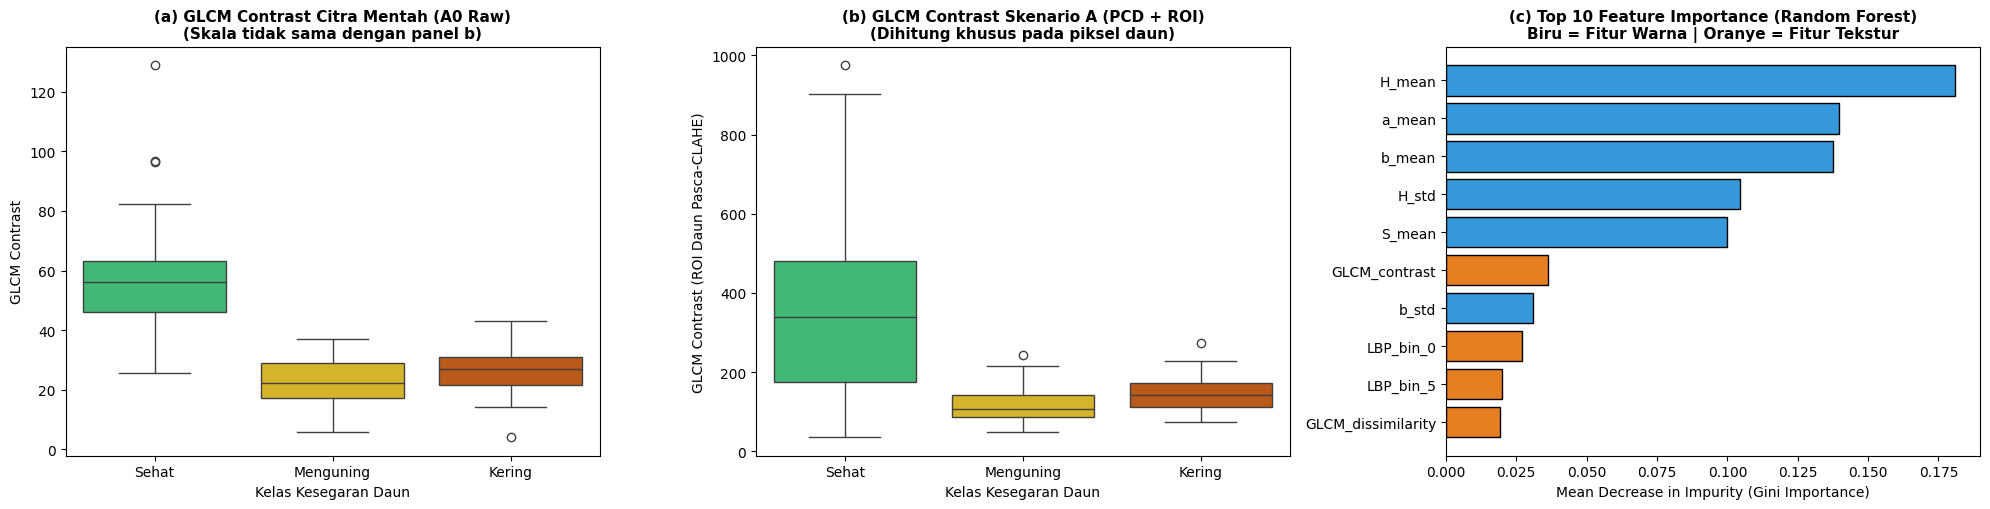

In [3]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

try:
    from skimage.feature import graycomatrix, graycoprops, local_binary_pattern
except ImportError:
    from skimage.feature import greycomatrix as graycomatrix, greycoprops as graycoprops, local_binary_pattern

OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2'
csv_master_path = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
df_master_p2 = pd.read_csv(csv_master_path)
assert 'gamma_used' in df_master_p2.columns, "CSV bukan v2!"

COLOR_COLS = [
    'H_mean', 'H_std', 'S_mean', 'S_std', 'V_mean', 'V_std',
    'L_mean', 'L_std', 'a_mean', 'a_std', 'b_mean', 'b_std'
]
GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
GLCM_COLS = [f'GLCM_{p}' for p in GLCM_PROPS]
LBP_COLS = [f'LBP_bin_{i}' for i in range(10)]
ALL_FEATURE_COLS = COLOR_COLS + GLCM_COLS + LBP_COLS

def extract_handcrafted_features(img_bgr, mask=None, use_mask=True):
    """Mengekstrak 12 fitur warna (HSV+LAB), 6 fitur GLCM, dan 10 bin histogram LBP uniform."""
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV).astype(np.float32)
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB).astype(np.float32)
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

    if use_mask and mask is not None and np.sum(mask > 0) > 50:
        valid = (mask > 0)
    else:
        valid = np.ones(gray.shape, dtype=bool)

    # 1. Ekstraksi 12 Fitur Statistik Warna (Mean & Std HSV + CIE-LAB)
    feats = {}
    for idx, ch_name in enumerate(['H', 'S', 'V']):
        vals = hsv[:, :, idx][valid]
        feats[f'{ch_name}_mean'] = float(np.mean(vals))
        feats[f'{ch_name}_std']  = float(np.std(vals))

    for idx, ch_name in enumerate(['L', 'a', 'b']):
        vals = lab[:, :, idx][valid]
        feats[f'{ch_name}_mean'] = float(np.mean(vals))
        feats[f'{ch_name}_std']  = float(np.std(vals))

    # 2. Ekstraksi 6 Fitur Tekstur Spasial GLCM (Jarak d=[1,2], 4 Sudut Arah)
    if use_mask and mask is not None and np.sum(mask > 0) > 50:
        gray_glcm = np.where(valid, np.clip(gray, 1, 255), 0).astype(np.uint8)
        glcm = graycomatrix(
            gray_glcm, distances=[1, 2],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=256, symmetric=True, normed=False
        )
        glcm[0, :, :, :] = 0
        glcm[:, 0, :, :] = 0
        glcm_sum = np.sum(glcm, axis=(0, 1), keepdims=True)
        glcm_norm = np.divide(glcm.astype(np.float64), glcm_sum, out=np.zeros_like(glcm, dtype=np.float64), where=glcm_sum > 0)
    else:
        glcm_norm = graycomatrix(
            gray, distances=[1, 2],
            angles=[0, np.pi/4, np.pi/2, 3*np.pi/4],
            levels=256, symmetric=True, normed=True
        )

    for prop in GLCM_PROPS:
        feats[f'GLCM_{prop}'] = float(np.mean(graycoprops(glcm_norm, prop)))

    # 3. Ekstraksi 10 Fitur Histogram Tekstur Lokal LBP (P=8, R=1, method='uniform')
    lbp = local_binary_pattern(gray, P=8, R=1, method='uniform')
    lbp_vals = lbp[valid]
    hist, _ = np.histogram(lbp_vals, bins=np.arange(0, 11), density=True)
    for i in range(10):
        feats[f'LBP_bin_{i}'] = float(hist[i])

    return feats

records_A0, records_C1, records_A = [], [], []

print("Mengekstrak 28 fitur (Warna + GLCM + LBP) pada 619 citra v2 (A0, C1, dan A)...")
for idx, row in tqdm(df_master_p2.iterrows(), total=len(df_master_p2)):
    meta = {
        'sample_id': row['sample_id'],
        'parent_id': row['parent_id'],
        'original_filename': row['original_filename'],
        'label': row['label'],
        'sesi': row['sesi'],
        'fold': row['fold'],
        'is_augmented': row['is_augmented'],
        'aug_type': row['aug_type']
    }

    img_a0 = cv2.imread(row['path_A0_raw'])
    img_c1 = cv2.imread(row['path_C1_nomask'])
    img_c2 = cv2.imread(row['path_C2_masked'])
    msk_c2 = cv2.imread(row['path_mask'], cv2.IMREAD_GRAYSCALE)
    if img_a0 is None or img_c1 is None or img_c2 is None or msk_c2 is None:
        raise FileNotFoundError(f"Gagal membaca citra/mask untuk {row['sample_id']}")

    records_A0.append({**meta, **extract_handcrafted_features(img_a0, mask=None, use_mask=False)})
    records_C1.append({**meta, **extract_handcrafted_features(img_c1, mask=None, use_mask=False)})
    records_A.append({**meta,  **extract_handcrafted_features(img_c2, mask=msk_c2, use_mask=True)})

df_feat_A0 = pd.DataFrame(records_A0)
df_feat_C1 = pd.DataFrame(records_C1)
df_feat_A  = pd.DataFrame(records_A)

path_csv_a0 = os.path.join(OUT_BASE, 'features_A0_raw_p2.csv')
path_csv_c1 = os.path.join(OUT_BASE, 'features_C1_nomask_p2.csv')
path_csv_a  = os.path.join(OUT_BASE, 'features_A_pcd_p2.csv')
df_feat_A0.to_csv(path_csv_a0, index=False)
df_feat_C1.to_csv(path_csv_c1, index=False)
df_feat_A.to_csv(path_csv_a, index=False)

print(f"\nSukses! Dimensi Tabel Fitur v2: {df_feat_A.shape} (619 sampel x {len(ALL_FEATURE_COLS)} fitur + 8 kolom metadata)")
print(f"- File Fitur A0 (Raw)      : {path_csv_a0}")
print(f"- File Fitur C1 (PCD Only) : {path_csv_c1}")
print(f"- File Fitur A  (PCD+ROI)  : {path_csv_a}")

# ==============================================================================
# VISUALISASI SEPARABILITAS GLCM CONTRAST & TOP 10 FEATURE IMPORTANCE (v2)
# ==============================================================================
df_orig_A0 = df_feat_A0[df_feat_A0['is_augmented'] == 0].copy()
df_orig_A  = df_feat_A[df_feat_A['is_augmented'] == 0].copy()

X_imp = StandardScaler().fit_transform(df_feat_A[ALL_FEATURE_COLS])
rf_imp = RandomForestClassifier(n_estimators=200, random_state=42, class_weight='balanced')
rf_imp.fit(X_imp, df_feat_A['label'])
imp_series = pd.Series(rf_imp.feature_importances_, index=ALL_FEATURE_COLS).sort_values(ascending=True)

palette_cls = {'Sehat': '#2ecc71', 'Menguning': '#f1c40f', 'Kering': '#d35400'}
fig, axes = plt.subplots(1, 3, figsize=(20, 5.2))

sns.boxplot(data=df_orig_A0, x='label', y='GLCM_contrast', hue='label', order=['Sehat', 'Menguning', 'Kering'], palette=palette_cls, legend=False, ax=axes[0])
axes[0].set_title('(a) GLCM Contrast Citra Mentah (A0 Raw)\n(Skala tidak sama dengan panel b)', fontsize=11, fontweight='bold')
axes[0].set_xlabel('Kelas Kesegaran Daun')
axes[0].set_ylabel('GLCM Contrast')

sns.boxplot(data=df_orig_A, x='label', y='GLCM_contrast', hue='label', order=['Sehat', 'Menguning', 'Kering'], palette=palette_cls, legend=False, ax=axes[1])
axes[1].set_title('(b) GLCM Contrast Skenario A (PCD + ROI)\n(Dihitung khusus pada piksel daun)', fontsize=11, fontweight='bold')
axes[1].set_xlabel('Kelas Kesegaran Daun')
axes[1].set_ylabel('GLCM Contrast (ROI Daun Pasca-CLAHE)')

top10_imp = imp_series.tail(10)
colors_bar = ['#e67e22' if ('GLCM' in c or 'LBP' in c) else '#3498db' for c in top10_imp.index]
axes[2].barh(top10_imp.index, top10_imp.values, color=colors_bar, edgecolor='black')
axes[2].set_title('(c) Top 10 Feature Importance (Random Forest)\nBiru = Fitur Warna | Oranye = Fitur Tekstur', fontsize=11, fontweight='bold')
axes[2].set_xlabel('Mean Decrease in Impurity (Gini Importance)')

plt.tight_layout()
plt.savefig('P2_Slide8_9_Separabilitas_GLCM_dan_Feature_Importance.png', dpi=300)
plt.savefig(os.path.join(OUT_BASE, 'P2_Slide8_9_Separabilitas_GLCM_dan_Feature_Importance.png'), dpi=300)
plt.show()

### Analisis Keluaran Sel 1 (Separabilitas Fitur & Feature Importance `v2`):
1. **Panel (a) vs (b) tidak dibandingkan secara angka mentah:** skala sumbu-$y$ berbeda karena `A0` menghitung GLCM pada citra `224×224` beserta latar kertas, sedangkan `A` menghitungnya hanya pada piksel daun yang di-*crop* ke ROI `224×224`. Yang diamati adalah urutan antar kelas: `Sehat` memiliki kontras lebih tinggi dan lebar, sedangkan `Menguning` dan `Kering` masih memiliki tumpang tindih sebagian.
2. **Dominasi Fitur Warna (Panel c):** 5 prediktor teratas pada Random Forest seluruhnya berasal dari fitur warna (`H_mean`, `a_mean`, `b_mean`, `H_std`, `S_mean`), sementara fitur tekstur pertama (`GLCM_contrast`) berada di peringkat 6. Temuan ini konsisten dengan studi ablasi pada Bagian 2 (Tabel 3).

## 2. Evaluasi Baseline ML Klasik (5-Fold CV): Komparasi PCD, Augmentasi, & Ablasi Fitur (`v2`)

**Tujuan:**
Mengevaluasi 3 keluarga algoritma Machine Learning klasik (**SVM RBF**, **Random Forest**, dan **KNN**) dengan **Stratified 5-Fold Cross-Validation Anti-Leakage** pada dataset `v2`:
- **Data Latih (*Train Set*):** seluruh sampel pada `fold != k`.
- **Data Uji (*Test Set*):** **wajib** murni foto asli (`is_augmented == 0`) pada `fold == k` ($N_{test} = 127$ foto asli melintasi 5 *fold*).
- Menghasilkan **Tabel 1 (A0 vs A)**, **Tabel 2 (Dampak Augmentasi)**, dan **Tabel 3 (Ablasi Warna vs Tekstur vs Fusi)**. Selisih Macro-F1 dilaporkan dalam satuan **poin (`poin Macro-F1`)**, serta dibaca berdampingan dengan uji **LOSO Cross-Session** pada Bagian 3B agar keunggulan PCD + ROI vs *shortcut* sesi terlihat utuh.

In [4]:
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

def get_ml_models():
    """Mendefinisikan 3 pipeline model ML klasik dengan normalisasi StandardScaler."""
    return {
        'SVM (RBF Kernel)': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(C=3.0, kernel='rbf', gamma='scale', class_weight='balanced', probability=True, random_state=42))
        ]),
        'Random Forest': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(n_estimators=200, max_depth=10, class_weight='balanced', random_state=42))
        ]),
        'KNN (k=7, Distance)': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier(n_neighbors=7, weights='distance'))
        ])
    }

def evaluate_5fold_anti_leakage(df_features, feature_cols, use_augmented_train=True):
    """Evaluasi 5-Fold CV bebas leakage parent_id; uji hanya pada citra asli (is_augmented == 0)."""
    models = get_ml_models()
    summary_rows = []
    oof_predictions = {}

    for model_name, pipe in models.items():
        fold_accs, fold_precs, fold_recs, fold_f1s = [], [], [], []
        y_true_all, y_pred_all, sample_ids_all = [], [], []

        for k in range(5):
            if use_augmented_train:
                train_df = df_features[df_features['fold'] != k]
            else:
                train_df = df_features[(df_features['fold'] != k) & (df_features['is_augmented'] == 0)]

            test_df = df_features[(df_features['fold'] == k) & (df_features['is_augmented'] == 0)]
            assert set(train_df['parent_id']).isdisjoint(set(test_df['parent_id'])), (
                f"KEBOCORAN parent_id pada fold {k}!"
            )

            X_train, y_train = train_df[feature_cols].values, train_df['label'].values
            X_test,  y_test  = test_df[feature_cols].values,  test_df['label'].values

            pipe.fit(X_train, y_train)
            y_pred = pipe.predict(X_test)

            fold_accs.append(accuracy_score(y_test, y_pred) * 100)
            fold_precs.append(precision_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_recs.append(recall_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0) * 100)

            y_true_all.extend(y_test)
            y_pred_all.extend(y_pred)
            sample_ids_all.extend(test_df['sample_id'].values)

        oof_predictions[model_name] = pd.DataFrame({
            'sample_id': sample_ids_all,
            'y_true': y_true_all,
            'y_pred': y_pred_all
        })

        summary_rows.append({
            'Model ML Klasik': model_name,
            'Accuracy (%)': f"{np.mean(fold_accs):.2f} ± {np.std(fold_accs):.2f}",
            'Macro-Precision (%)': f"{np.mean(fold_precs):.2f} ± {np.std(fold_precs):.2f}",
            'Macro-Recall (%)': f"{np.mean(fold_recs):.2f} ± {np.std(fold_recs):.2f}",
            'Macro-F1 (%)': f"{np.mean(fold_f1s):.2f} ± {np.std(fold_f1s):.2f}",
            '_f1_mean': np.mean(fold_f1s),
            '_acc_mean': np.mean(fold_accs)
        })

    return pd.DataFrame(summary_rows), oof_predictions

# 1. TABEL 1: A0 (CITRA MENTAH) VS A (PCD + ROI DAUN)
df_res_A0, oof_A0 = evaluate_5fold_anti_leakage(df_feat_A0, ALL_FEATURE_COLS, use_augmented_train=True)
df_res_A,  oof_A  = evaluate_5fold_anti_leakage(df_feat_A,  ALL_FEATURE_COLS, use_augmented_train=True)

df_res_A0['Skenario'] = 'A0: Raw Image + Fitur + ML'
df_res_A['Skenario']  = 'A: PCD Lengkap (C2) + Fitur + ML'
df_table1 = pd.concat([df_res_A0, df_res_A], ignore_index=True)[
    ['Skenario', 'Model ML Klasik', 'Accuracy (%)', 'Macro-Precision (%)', 'Macro-Recall (%)', 'Macro-F1 (%)']
]

print("=" * 92)
print("TABEL 1 (v2): KOMPARASI SKENARIO A0 (RAW) VS SKENARIO A (PCD LENGKAP + ROI) - 5-FOLD ACAK")
print("=" * 92)
print(df_table1.to_string(index=False))

# 2. TABEL 2: DAMPAK AUGMENTASI (latih asli saja N=127 vs asli+sintetis N=619; uji foto asli)
df_res_no_aug, _ = evaluate_5fold_anti_leakage(df_feat_A, ALL_FEATURE_COLS, use_augmented_train=False)
df_table2 = pd.DataFrame({
    'Model ML Klasik': df_res_A['Model ML Klasik'],
    'Macro-F1 Tanpa Augmentasi (N=127)': df_res_no_aug['Macro-F1 (%)'],
    'Macro-F1 Dengan Augmentasi (N=619)': df_res_A['Macro-F1 (%)'],
    'Selisih (poin Macro-F1)': [f"{a - b:+.2f}" for a, b in zip(df_res_A['_f1_mean'], df_res_no_aug['_f1_mean'])]
})

print("\n" + "=" * 92)
print("TABEL 2 (v2): DAMPAK AUGMENTASI PADA SKENARIO A (selisih dalam poin Macro-F1)")
print("=" * 92)
print(df_table2.to_string(index=False))

# 3. TABEL 3: STUDI ABLASI FITUR (Warna vs Tekstur vs Fusi)
df_abl_color, _   = evaluate_5fold_anti_leakage(df_feat_A, COLOR_COLS, use_augmented_train=True)
df_abl_texture, _ = evaluate_5fold_anti_leakage(df_feat_A, GLCM_COLS + LBP_COLS, use_augmented_train=True)

df_table3 = pd.DataFrame({
    'Model ML Klasik': df_res_A['Model ML Klasik'],
    'Warna Saja (12 Fitur HSV+LAB)': df_abl_color['Macro-F1 (%)'],
    'Tekstur Saja (16 Fitur GLCM+LBP)': df_abl_texture['Macro-F1 (%)'],
    'Fusi Warna + Tekstur (28 Fitur)': df_res_A['Macro-F1 (%)'],
    'Selisih Fusi - Warna (poin)': [f"{full - col:+.2f}" for full, col in zip(df_res_A['_f1_mean'], df_abl_color['_f1_mean'])]
})

print("\n" + "=" * 92)
print("TABEL 3 (v2): STUDI ABLASI FITUR PADA SKENARIO A (WARNA VS TEKSTUR VS FUSI)")
print("=" * 92)
print(df_table3.to_string(index=False))

df_table1.to_csv(os.path.join(OUT_BASE, 'P2_Tabel1_Komparasi_A0_vs_A.csv'), index=False)
df_table2.to_csv(os.path.join(OUT_BASE, 'P2_Tabel2_Dampak_Augmentasi.csv'), index=False)
df_table3.to_csv(os.path.join(OUT_BASE, 'P2_Tabel3_Ablasi_Fitur_RQ1.csv'), index=False)

oof_rows_a0 = [df.assign(model=m_name) for m_name, df in oof_A0.items()]
oof_rows_a  = [df.assign(model=m_name) for m_name, df in oof_A.items()]
pd.concat(oof_rows_a0, ignore_index=True).to_csv(os.path.join(OUT_BASE, 'oof_ml_A0_p2.csv'), index=False)
pd.concat(oof_rows_a,  ignore_index=True).to_csv(os.path.join(OUT_BASE, 'oof_ml_A_p2.csv'), index=False)

TABEL 1 (v2): KOMPARASI SKENARIO A0 (RAW) VS SKENARIO A (PCD LENGKAP + ROI) - 5-FOLD ACAK
                        Skenario     Model ML Klasik Accuracy (%) Macro-Precision (%) Macro-Recall (%) Macro-F1 (%)
      A0: Raw Image + Fitur + ML    SVM (RBF Kernel) 92.92 ± 6.23        94.42 ± 4.81     93.10 ± 5.97 92.73 ± 6.35
      A0: Raw Image + Fitur + ML       Random Forest 92.92 ± 5.10        94.00 ± 4.18     93.10 ± 4.19 92.77 ± 4.97
      A0: Raw Image + Fitur + ML KNN (k=7, Distance) 93.72 ± 5.79        94.40 ± 4.82     94.17 ± 4.95 93.70 ± 5.66
A: PCD Lengkap (C2) + Fitur + ML    SVM (RBF Kernel) 88.98 ± 4.59        90.54 ± 4.15     88.79 ± 5.33 88.36 ± 5.34
A: PCD Lengkap (C2) + Fitur + ML       Random Forest 91.35 ± 2.92        91.56 ± 3.27     91.36 ± 3.08 91.17 ± 3.06
A: PCD Lengkap (C2) + Fitur + ML KNN (k=7, Distance) 80.34 ± 2.26        81.63 ± 3.43     81.06 ± 2.53 80.18 ± 2.14

TABEL 2 (v2): DAMPAK AUGMENTASI PADA SKENARIO A (selisih dalam poin Macro-F1)
    Model ML Klasik

## 3. Visualisasi Confusion Matrix $3 \times 3$ (A0 vs A) & Diagnosis Error Analysis (`v2`)

**Tujuan:**
1. Membandingkan **Confusion Matrix $3 \times 3$** (*Out-of-Fold* pada 127 citra asli `v2`) antara **A0** dan **A** pada model baseline terbaik.
2. Menampilkan daftar lengkap sampel salah klasifikasi beserta ringkasan per sesi dan inspeksi visual hingga 8 sampel galat.

Model ML Klasik Terbaik (Baseline 5-Fold Skenario A v2): Random Forest



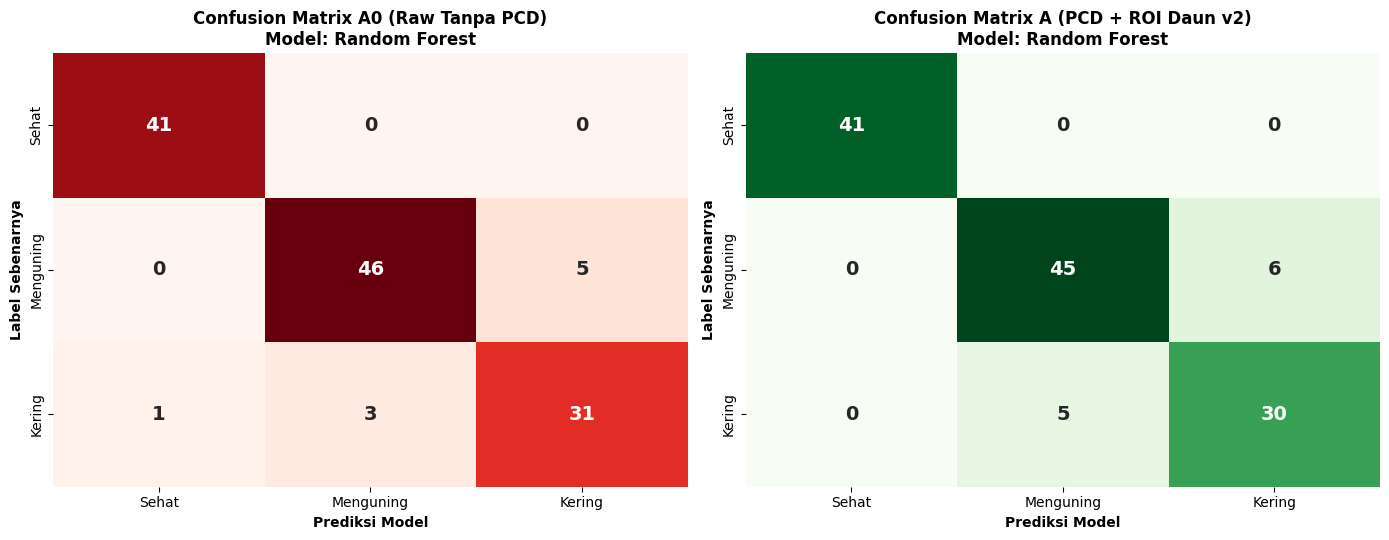

=== CLASSIFICATION REPORT PER KELAS (Random Forest - SKENARIO A v2) ===
              precision    recall  f1-score   support

       Sehat     1.0000    1.0000    1.0000        41
   Menguning     0.9000    0.8824    0.8911        51
      Kering     0.8333    0.8571    0.8451        35

    accuracy                         0.9134       127
   macro avg     0.9111    0.9132    0.9121       127
weighted avg     0.9139    0.9134    0.9136       127

A  (PCD + ROI): 11 dari 127 foto asli salah.
    sample_id       original_filename  sesi    y_true    y_pred
LEAF_057_orig IMG_20261022_154520.jpg     1 Menguning    Kering
LEAF_074_orig IMG_20261022_155435.jpg     1 Menguning    Kering
LEAF_115_orig IMG_20261022_155817.jpg     1    Kering Menguning
LEAF_058_orig IMG_20261022_154522.jpg     1 Menguning    Kering
LEAF_061_orig IMG_20261022_154553.jpg     1 Menguning    Kering
LEAF_073_orig IMG_20261022_155402.jpg     1 Menguning    Kering
LEAF_097_orig IMG_20261022_154642.jpg     1    Kering 

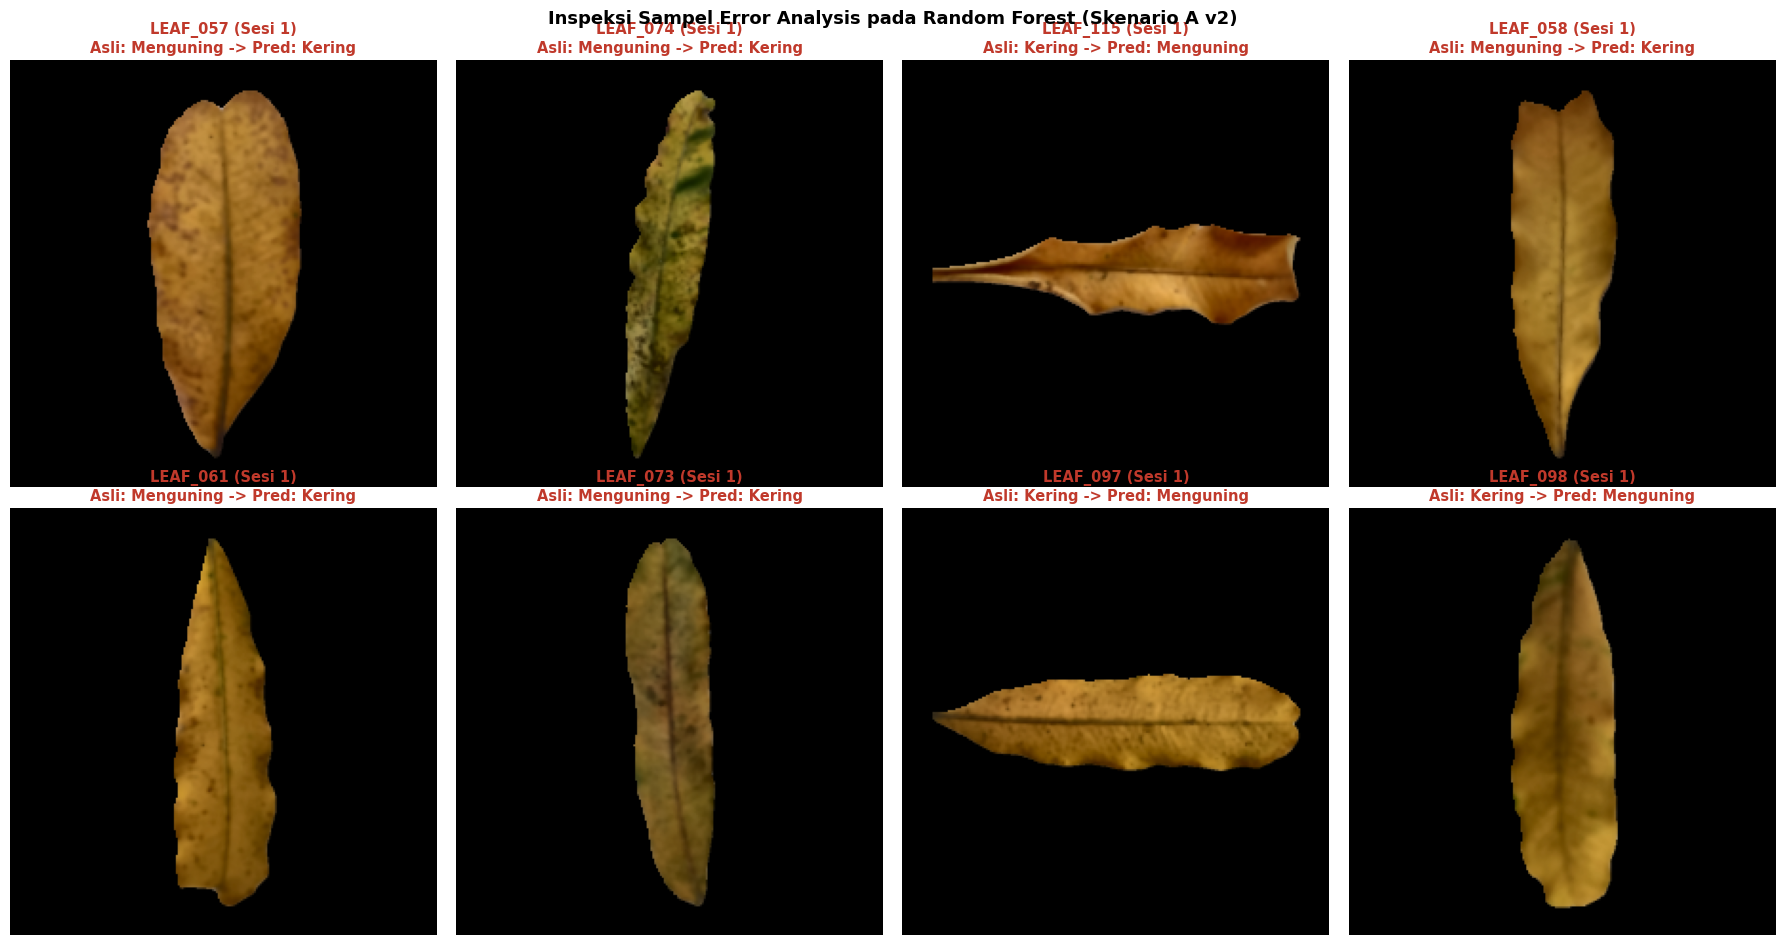

In [5]:
from sklearn.metrics import confusion_matrix, classification_report

best_model_name = df_res_A.sort_values(by='_f1_mean', ascending=False).iloc[0]['Model ML Klasik']
print(f"Model ML Klasik Terbaik (Baseline 5-Fold Skenario A v2): {best_model_name}\n")

labels_order = ['Sehat', 'Menguning', 'Kering']
oof_best_A0 = oof_A0[best_model_name]
oof_best_A  = oof_A[best_model_name]

cm_A0 = confusion_matrix(oof_best_A0['y_true'], oof_best_A0['y_pred'], labels=labels_order)
cm_A  = confusion_matrix(oof_best_A['y_true'],  oof_best_A['y_pred'],  labels=labels_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(cm_A0, annot=True, fmt='d', cmap='Reds', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[0])
axes[0].set_title(f'Confusion Matrix A0 (Raw Tanpa PCD)\nModel: {best_model_name}', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Prediksi Model', fontweight='bold')
axes[0].set_ylabel('Label Sebenarnya', fontweight='bold')

sns.heatmap(cm_A, annot=True, fmt='d', cmap='Greens', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[1])
axes[1].set_title(f'Confusion Matrix A (PCD + ROI Daun v2)\nModel: {best_model_name}', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Prediksi Model', fontweight='bold')
axes[1].set_ylabel('Label Sebenarnya', fontweight='bold')

plt.tight_layout()
plt.savefig('P2_Slide12_Confusion_Matrix_A0_vs_A.png', dpi=300)
plt.savefig(os.path.join(OUT_BASE, 'P2_Slide12_Confusion_Matrix_A0_vs_A.png'), dpi=300)
plt.show()

print(f"=== CLASSIFICATION REPORT PER KELAS ({best_model_name} - SKENARIO A v2) ===")
print(classification_report(oof_best_A['y_true'], oof_best_A['y_pred'], labels=labels_order, digits=4))

meta_cols = ['sample_id', 'parent_id', 'original_filename', 'sesi', 'path_C1_nomask', 'path_C2_masked']
def _error_table(oof_df):
    e = oof_df[oof_df['y_true'] != oof_df['y_pred']].copy()
    return e.merge(df_master_p2[meta_cols], on='sample_id', how='left')

df_errors   = _error_table(oof_best_A)
df_errors_0 = _error_table(oof_best_A0)

print(f"A  (PCD + ROI): {len(df_errors)} dari 127 foto asli salah.")
print(df_errors[['sample_id', 'original_filename', 'sesi', 'y_true', 'y_pred']].to_string(index=False))
if len(df_errors) > 0:
    print("\nRingkasan galat A per (sesi, label benar -> prediksi):")
    print(df_errors.groupby(['sesi', 'y_true', 'y_pred']).size().to_string())

print(f"\nA0 (Raw): {len(df_errors_0)} dari 127 foto asli salah.")
print(df_errors_0[['sample_id', 'original_filename', 'sesi', 'y_true', 'y_pred']].to_string(index=False))
both_err = sorted(set(df_errors['parent_id']) & set(df_errors_0['parent_id']))
print(f"\nGalat identik pada A dan A0: {len(both_err)} foto -> {both_err}")

if len(df_errors) > 0:
    n_show = min(8, len(df_errors))
    cols = min(4, n_show)
    rows_ = int(np.ceil(n_show / cols))
    fig, axes = plt.subplots(rows_, cols, figsize=(4.5 * cols, 4.8 * rows_))
    axes = np.atleast_1d(axes).ravel()
    for ax in axes:
        ax.axis('off')
    for idx_err, (_, err_row) in enumerate(df_errors.iloc[:n_show].iterrows()):
        img_err = cv2.imread(err_row['path_C2_masked'])
        axes[idx_err].imshow(cv2.cvtColor(img_err, cv2.COLOR_BGR2RGB))
        axes[idx_err].set_title(
            f"{err_row['parent_id']} (Sesi {err_row['sesi']})\n"
            f"Asli: {err_row['y_true']} -> Pred: {err_row['y_pred']}",
            fontsize=10.5, fontweight='bold', color='#c0392b'
        )
    plt.suptitle(f"Inspeksi Sampel Error Analysis pada {best_model_name} (Skenario A v2)", fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('P2_Slide13_Error_Analysis_Samples.png', dpi=300, bbox_inches='tight')
    plt.savefig(os.path.join(OUT_BASE, 'P2_Slide13_Error_Analysis_Samples.png'), dpi=300, bbox_inches='tight')
    plt.show()

### Analisis Keluaran Sel 3 (Error Analysis `v2`):
1. **Konsentrasi Galat pada Zona Transisi (`Menguning` $\leftrightarrow$ `Kering`):** Seluruh kelas `Sehat` terklasifikasi 100% (`41/41`). Seluruh galat Skenario A berasal dari perbatasan `Menguning` $\leftrightarrow$ `Kering` pada **Sesi 1** (di mana 10 foto juga sebelumnya direlabel secara visual saat audit P1).
2. **Alasan Menuju Progress 3 (Deep Learning):** Fitur *global averaging* merata-ratakan seluruh piksel daun, sehingga daun berbercak nekrosis parsial di ujung/tengah sulit dipisahkan dari daun kuning rata. Pada Progress 3, model konvolusional (**MobileNetV2/V3**, **YOLOv8/v11-cls**) diuji pada protokol split yang sama (termasuk **LOSO**) untuk membandingkan performa representasi spasial hierarkis.

## 3B. Evaluasi Lintas Sesi (LOSO `E1` & `E8`), CV Berulang (`E2`), & Uji McNemar (`E3`) (`v2`)

**Tujuan:** Menguji apakah keunggulan `A0` pada 5-fold acak bertahan ketika diuji **lintas sesi** (`Train Sesi 1 → Test Sesi 2` dan sebaliknya), serta memisahkan kontribusi **PCD tanpa topeng (`C1`)** vs **PCD + topeng ROI (`A`)**.

In [6]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone
from sklearn.metrics import f1_score, accuracy_score
from scipy.stats import binomtest

def add_repeated_folds(df, seeds=(0, 1, 2)):
    df = df.copy()
    orig = df[df['is_augmented'] == 0][['parent_id', 'label']].drop_duplicates().reset_index(drop=True)
    for s in seeds:
        fmap = {}
        for k, (_, va) in enumerate(StratifiedKFold(5, shuffle=True, random_state=s).split(orig, orig['label'])):
            for pid in orig.loc[va, 'parent_id']:
                fmap[pid] = k
        df[f'fold_s{s}'] = df['parent_id'].map(fmap)
    return df

def cv_repeated(df, cols, pipe, fold_cols=('fold', 'fold_s0', 'fold_s1', 'fold_s2'), use_aug=True):
    f1s, oof = [], {}
    for fc in fold_cols:
        pred = pd.Series(index=df[df['is_augmented'] == 0]['sample_id'], dtype=object)
        for k in range(5):
            tr = df[df[fc] != k]
            if not use_aug:
                tr = tr[tr['is_augmented'] == 0]
            te = df[(df[fc] == k) & (df['is_augmented'] == 0)]
            assert set(tr['parent_id']).isdisjoint(te['parent_id']), 'KEBOCORAN parent_id'
            m = clone(pipe).fit(tr[cols].values, tr['label'].values)
            p = m.predict(te[cols].values)
            f1s.append(f1_score(te['label'], p, average='macro') * 100)
            pred.loc[te['sample_id'].values] = p
        oof[fc] = pred
    return np.array(f1s), oof

def eval_loso_single(df, cols, pipe, train_sesi, use_aug=True):
    tr = df[df['sesi'] == train_sesi]
    if not use_aug:
        tr = tr[tr['is_augmented'] == 0]
    te = df[(df['sesi'] != train_sesi) & (df['is_augmented'] == 0)]
    assert set(tr['parent_id']).isdisjoint(te['parent_id']), 'KEBOCORAN parent_id'
    m = clone(pipe).fit(tr[cols].values, tr['label'].values)
    p = m.predict(te[cols].values)
    maj = te['label'].value_counts(normalize=True).max() * 100
    return f1_score(te['label'], p, average='macro') * 100, accuracy_score(te['label'], p) * 100, maj

def mcnemar_exact(y, pa, pb):
    a_ok, b_ok = (np.asarray(pa) == np.asarray(y)), (np.asarray(pb) == np.asarray(y))
    n01, n10 = int((~a_ok & b_ok).sum()), int((a_ok & ~b_ok).sum())
    p = 1.0 if n01 + n10 == 0 else binomtest(min(n01, n10), n01 + n10, 0.5).pvalue
    return n01, n10, p

dA0 = add_repeated_folds(df_feat_A0)
dC1 = add_repeated_folds(df_feat_C1)
dA  = add_repeated_folds(df_feat_A)

ml_models = get_ml_models()
rows_cv, rows_loso, rows_mc, rows_abl, rows_e9 = [], [], [], [], []
oofs_rep = {}

for mname, pipe in ml_models.items():
    for scen, d in (('A0 (mentah)', dA0), ('C1 (PCD tanpa topeng)', dC1), ('A (PCD+ROI)', dA)):
        if scen != 'C1 (PCD tanpa topeng)':
            f, oof = cv_repeated(d, ALL_FEATURE_COLS, pipe)
            oofs_rep[(mname, scen)] = oof
            rows_cv.append(dict(Model=mname, Skenario=scen, **{'Macro-F1 20 lipatan': f"{f.mean():.1f} ± {f.std():.1f}"}))
        for tr_s in (1, 2):
            f1_, acc_, maj_ = eval_loso_single(d, ALL_FEATURE_COLS, pipe, tr_s, use_aug=True)
            rows_loso.append(dict(Model=mname, Skenario=scen, Latih=f'Sesi {tr_s}', Uji=f'Sesi {3 - tr_s}',
                                  **{'Macro-F1': round(f1_, 1), 'Akurasi': round(acc_, 1), 'Baseline mayoritas': round(maj_, 1)}))

    # E3: McNemar A0 vs A pada OOF 5-fold standar
    yv = dA[dA['is_augmented'] == 0].set_index('sample_id').loc[oofs_rep[(mname, 'A0 (mentah)')]['fold'].index, 'label']
    n01, n10, p = mcnemar_exact(yv.values, oofs_rep[(mname, 'A0 (mentah)')]['fold'].values, oofs_rep[(mname, 'A (PCD+ROI)')]['fold'].values)
    rows_mc.append(dict(Model=mname, **{'A0 benar & A salah': n10, 'A0 salah & A benar': n01, 'p (McNemar eksak)': round(p, 3)}))

    # E4: Paired ablation warna vs fusi (20 lipatan)
    f_col, _ = cv_repeated(dA, COLOR_COLS, pipe)
    f_all, _ = cv_repeated(dA, ALL_FEATURE_COLS, pipe)
    dlt = f_all - f_col
    rows_abl.append(dict(Model=mname, **{'F1 warna': f"{f_col.mean():.1f}", 'F1 fusi': f"{f_all.mean():.1f}",
                                         'Δ (fusi−warna) rata-rata ± SD': f"{dlt.mean():+.1f} ± {dlt.std():.1f}",
                                         'Fusi ≥ warna (dari 20)': int((dlt >= 0).sum())}))

    # E9: Dampak augmentasi pada LOSO Skenario A
    for tr_s in (1, 2):
        for use_aug in (False, True):
            f1_, acc_, _ = eval_loso_single(dA, ALL_FEATURE_COLS, pipe, tr_s, use_aug=use_aug)
            rows_e9.append(dict(Model=mname, Latih=f'Sesi {tr_s}', Augmentasi='dengan' if use_aug else 'tanpa',
                                **{'Macro-F1': round(f1_, 1), 'Akurasi': round(acc_, 1)}))

df_e2, df_loso_all, df_e3, df_e4, df_e9 = map(pd.DataFrame, (rows_cv, rows_loso, rows_mc, rows_abl, rows_e9))
print("E2  Macro-F1, 5-fold × 4 pengacakan (20 nilai):"); print(df_e2.to_string(index=False))
print("\nE1 & E8  LOSO Cross-Session (A0 vs C1 tanpa topeng vs A PCD+ROI): Macro-F1")
print(df_loso_all.pivot_table(index=['Model', 'Latih'], columns='Skenario', values='Macro-F1').round(1).to_string())
print("\nE3  McNemar eksak A0 vs A (5-fold OOF):"); print(df_e3.to_string(index=False))
print("\nE4  Ablasi berpasangan warna vs fusi (20 lipatan):"); print(df_e4.to_string(index=False))
print("\nE9  LOSO Skenario A tanpa vs dengan augmentasi:")
print(df_e9.pivot_table(index=['Model', 'Latih'], columns='Augmentasi', values='Macro-F1').round(1).to_string())

for nm, d_ in (('E1_E8_LOSO', df_loso_all), ('E2_CV_berulang', df_e2), ('E3_McNemar', df_e3), ('E4_Ablasi_berpasangan', df_e4), ('E9_Augmentasi_LOSO', df_e9)):
    d_.to_csv(os.path.join(OUT_BASE, f'P2_{nm}.csv'), index=False)

E2  Macro-F1, 5-fold × 4 pengacakan (20 nilai):
              Model    Skenario Macro-F1 20 lipatan
   SVM (RBF Kernel) A0 (mentah)          93.3 ± 4.9
   SVM (RBF Kernel) A (PCD+ROI)          91.2 ± 5.9
      Random Forest A0 (mentah)          91.1 ± 4.9
      Random Forest A (PCD+ROI)          91.1 ± 5.8
KNN (k=7, Distance) A0 (mentah)          92.0 ± 6.3
KNN (k=7, Distance) A (PCD+ROI)          82.8 ± 5.5

E1 & E8  LOSO Cross-Session (A0 vs C1 tanpa topeng vs A PCD+ROI): Macro-F1
Skenario                    A (PCD+ROI)  A0 (mentah)  C1 (PCD tanpa topeng)
Model               Latih                                                  
KNN (k=7, Distance) Sesi 1         91.3         16.3                   17.9
                    Sesi 2         62.9         22.8                   31.4
Random Forest       Sesi 1        100.0         16.3                   12.6
                    Sesi 2         83.7         15.9                   17.4
SVM (RBF Kernel)    Sesi 1         94.2         34.7    

---
## 4. Hyperparameter Tuning Anti-Leakage (*Nested 5-Fold CV*) (`v2`)

**Tujuan:**  
Mencari hyperparameter terbaik secara sistematis pada data **`v2`** tanpa kebocoran data augmentasi:
- **Outer CV (5-Fold):** Menggunakan kolom `fold` (`0..4`) dari `dataset_master_p2.csv` (`v2`); data uji **wajib** murni foto asli (`is_augmented == 0`).
- **Inner CV (`StratifiedGroupKFold` dengan `groups=parent_id`):** Di dalam `train_df` (`fold != k`), variasi asli & augmentasi dari `parent_id` yang sama dikunci agar **selalu berada di fold yang sama**.
- Selain mengevaluasi model utama **Fusi 28 Fitur** (Tabel 4), sel ini juga menguji **LOSO Cross-Session pasca-tuning** dan membandingkan performa tuning apabila hanya menggunakan **12 Fitur Warna (`COLOR_COLS`)**.

Menjalankan Nested 5-Fold CV Tuning [Fusi 28 Fitur] (Anti-Leakage by parent_id)...

[Fusi 28 Fitur - SVM (RBF Kernel)] Best Params per Fold:
  Fold 0: {'clf__C': 3.0, 'clf__gamma': 0.01}
  Fold 1: {'clf__C': 1.0, 'clf__gamma': 'scale'}
  Fold 2: {'clf__C': 0.5, 'clf__gamma': 0.01}
  Fold 3: {'clf__C': 3.0, 'clf__gamma': 0.01}
  Fold 4: {'clf__C': 0.5, 'clf__gamma': 0.01}

[Fusi 28 Fitur - Random Forest] Best Params per Fold:
  Fold 0: {'clf__max_depth': 6, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 4, 'clf__n_estimators': 300}
  Fold 1: {'clf__max_depth': 10, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 100}
  Fold 2: {'clf__max_depth': 10, 'clf__max_features': 'log2', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 100}
  Fold 3: {'clf__max_depth': 15, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 1, 'clf__n_estimators': 200}
  Fold 4: {'clf__max_depth': 6, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators'

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.84263865 0.84263865 0.84695058 0.84891193 0.84318774 0.83918783
 0.8491432  0.84908965 0.83889504 0.84478691        nan 0.82899298
        nan 0.84308997        nan 0.8409144         nan 0.84877465
        nan 0.86075114]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.79042075 0.79042075 0.80839659 0.81195389 0.8142498  0.81619282
 0.82035531 0.8264099  0.83014432 0.83754431        nan 0.81800923
        nan 0.81465973        nan 0.81008148        nan 0.81324751
        nan 0.84465271]
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_search.py:1108: UserWarning: One or more of the test scores are non-finite: [0.89892419 0.89892419 0.89890339 0.89890339 0.88516528 0.88718358
 0.88898655 0.89110881 0.9


[Fusi 28 Fitur - KNN] Best Params per Fold:
  Fold 0: {'clf__metric': 'manhattan', 'clf__n_neighbors': 11, 'clf__weights': 'distance'}
  Fold 1: {'clf__metric': 'manhattan', 'clf__n_neighbors': 11, 'clf__weights': 'distance'}
  Fold 2: {'clf__metric': 'manhattan', 'clf__n_neighbors': 11, 'clf__weights': 'distance'}
  Fold 3: {'clf__metric': 'manhattan', 'clf__n_neighbors': 11, 'clf__weights': 'distance'}
  Fold 4: {'clf__metric': 'euclidean', 'clf__n_neighbors': 11, 'clf__weights': 'distance'}

TABEL 4 (v2): PERBANDINGAN SKENARIO A (DEFAULT VS TUNED NESTED 5-FOLD CV)
 Model ML Klasik Macro-F1 Default (%) Macro-F1 Tuned (%) Selisih (poin Macro-F1) Accuracy Tuned (%)
SVM (RBF Kernel)         88.36 ± 5.34       89.62 ± 7.32                   +1.27       89.75 ± 7.22
   Random Forest         91.17 ± 3.06       92.70 ± 4.70                   +1.53       92.89 ± 4.57
             KNN         80.18 ± 2.14       87.22 ± 5.22                   +7.04       87.45 ± 5.12

Model Terbaik Pasca-Tuni

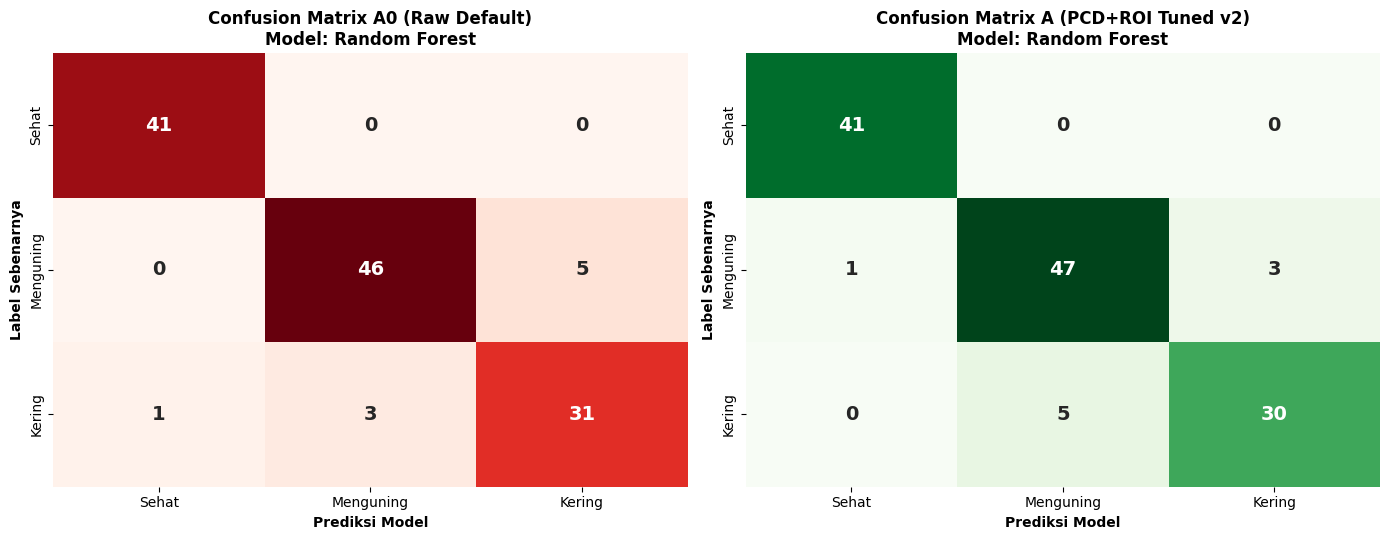


=== UJI LOSO CROSS-SESSION PASCA-TUNING (SKENARIO A v2) ===
 Model ML Klasik                                                                                         Konsensus Params     Latih -> Uji  Macro-F1 Tuned (%)  Accuracy Tuned (%)
SVM (RBF Kernel)                                                                      {'clf__C': 3.0, 'clf__gamma': 0.01} Sesi 1 -> Sesi 2               97.10               97.62
SVM (RBF Kernel)                                                                      {'clf__C': 3.0, 'clf__gamma': 0.01} Sesi 2 -> Sesi 1               77.37               75.29
   Random Forest {'clf__max_depth': 6, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 300} Sesi 1 -> Sesi 2              100.00              100.00
   Random Forest {'clf__max_depth': 6, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 300} Sesi 2 -> Sesi 1               83.68               82.35
             KNN                         {'c

In [7]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix
)

OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2'
_csv_master_p2 = os.path.join(OUT_BASE, 'dataset_master_p2.csv')
if os.path.exists(_csv_master_p2):
    df_master_p2 = pd.read_csv(_csv_master_p2)
    assert 'gamma_used' in df_master_p2.columns, "CSV bukan format v2!"

if 'ALL_FEATURE_COLS' not in globals():
    COLOR_COLS = [
        'H_mean', 'H_std', 'S_mean', 'S_std', 'V_mean', 'V_std',
        'L_mean', 'L_std', 'a_mean', 'a_std', 'b_mean', 'b_std'
    ]
    GLCM_PROPS = ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']
    GLCM_COLS = [f'GLCM_{p}' for p in GLCM_PROPS]
    LBP_COLS = [f'LBP_bin_{i}' for i in range(10)]
    ALL_FEATURE_COLS = COLOR_COLS + GLCM_COLS + LBP_COLS

_csv_a_path = os.path.join(OUT_BASE, 'features_A_pcd_p2.csv')
if 'df_feat_A' not in globals() and os.path.exists(_csv_a_path):
    df_feat_A = pd.read_csv(_csv_a_path)

if 'df_feat_A' not in globals() or len(df_feat_A) != len(df_master_p2):
    raise RuntimeError("Jalankan Sel Ekstraksi Fitur (Bagian 1) terlebih dahulu agar df_feat_A v2 tersedia di memori.")

tuning_configs = {
    'SVM (RBF Kernel)': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', SVC(kernel='rbf', class_weight='balanced', probability=True, random_state=42))
        ]),
        'param_grid': {
            'clf__C': [0.5, 1.0, 3.0, 10.0, 30.0],
            'clf__gamma': ['scale', 'auto', 0.01, 0.05, 0.1]
        }
    },
    'Random Forest': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', RandomForestClassifier(class_weight='balanced', random_state=42))
        ]),
        'param_grid': {
            'clf__n_estimators': [100, 200, 300],
            'clf__max_depth': [6, 10, 15, None],
            'clf__min_samples_leaf': [1, 2, 4],
            'clf__max_features': ['sqrt', 'log2']
        }
    },
    'KNN': {
        'pipeline': Pipeline([
            ('scaler', StandardScaler()),
            ('clf', KNeighborsClassifier())
        ]),
        'param_grid': {
            'clf__n_neighbors': [3, 5, 7, 9, 11],
            'clf__weights': ['uniform', 'distance'],
            'clf__metric': ['euclidean', 'manhattan']
        }
    }
}

def run_nested_tuning(df_feat, feat_cols, label_desc="28 Fitur"):
    inner_cv = StratifiedGroupKFold(n_splits=4)
    summary_rows, oof_dict = [], {}
    fold_models = {name: {} for name in tuning_configs}
    params_hist = {name: [] for name in tuning_configs}

    print(f"Menjalankan Nested 5-Fold CV Tuning [{label_desc}] (Anti-Leakage by parent_id)...")
    for model_name, cfg in tuning_configs.items():
        fold_accs, fold_precs, fold_recs, fold_f1s = [], [], [], []
        y_true_all, y_pred_all, sample_ids_all, fold_ids_all = [], [], [], []

        for k in range(5):
            train_df = df_feat[df_feat['fold'] != k].copy()
            test_df  = df_feat[(df_feat['fold'] == k) & (df_feat['is_augmented'] == 0)].copy()

            assert set(train_df['parent_id']).isdisjoint(set(test_df['parent_id'])), (
                f"Leakage terdeteksi pada outer fold {k}!"
            )
            assert (test_df['is_augmented'] == 0).all(), "Data uji harus murni citra asli!"

            X_train, y_train, groups_train = train_df[feat_cols].values, train_df['label'].values, train_df['parent_id'].values
            X_test,  y_test                = test_df[feat_cols].values,  test_df['label'].values

            if k == 0:
                for tr_idx, va_idx in inner_cv.split(X_train, y_train, groups=groups_train):
                    assert set(groups_train[tr_idx]).isdisjoint(set(groups_train[va_idx])), (
                        "Leakage terdeteksi pada inner StratifiedGroupKFold!"
                    )

            grid = GridSearchCV(
                estimator=cfg['pipeline'],
                param_grid=cfg['param_grid'],
                cv=inner_cv,
                scoring='f1_macro',
                n_jobs=-1,
                refit=True
            )
            grid.fit(X_train, y_train, groups=groups_train)

            best_est = grid.best_estimator_
            fold_models[model_name][k] = best_est
            params_hist[model_name].append(grid.best_params_)

            y_pred = best_est.predict(X_test)
            fold_accs.append(accuracy_score(y_test, y_pred) * 100)
            fold_precs.append(precision_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_recs.append(recall_score(y_test, y_pred, average='macro', zero_division=0) * 100)
            fold_f1s.append(f1_score(y_test, y_pred, average='macro', zero_division=0) * 100)

            y_true_all.extend(y_test)
            y_pred_all.extend(y_pred)
            sample_ids_all.extend(test_df['sample_id'].values)
            fold_ids_all.extend(test_df['fold'].values)

        oof_dict[model_name] = pd.DataFrame({
            'sample_id': sample_ids_all, 'fold': fold_ids_all,
            'y_true': y_true_all, 'y_pred': y_pred_all
        })
        summary_rows.append({
            'Model ML Klasik': model_name,
            'Accuracy (%)': f"{np.mean(fold_accs):.2f} ± {np.std(fold_accs):.2f}",
            'Macro-Precision (%)': f"{np.mean(fold_precs):.2f} ± {np.std(fold_precs):.2f}",
            'Macro-Recall (%)': f"{np.mean(fold_recs):.2f} ± {np.std(fold_recs):.2f}",
            'Macro-F1 Tuned (%)': f"{np.mean(fold_f1s):.2f} ± {np.std(fold_f1s):.2f}",
            '_f1_mean': np.mean(fold_f1s),
            '_acc_mean': np.mean(fold_accs)
        })
        print(f"\n[{label_desc} - {model_name}] Best Params per Fold:")
        for f_idx, bp in enumerate(params_hist[model_name]):
            print(f"  Fold {f_idx}: {bp}")

    return pd.DataFrame(summary_rows), oof_dict, fold_models, params_hist

# 1. Nested CV utama pada Fusi 28 Fitur (Skenario A v2)
df_res_tuned, oof_tuned_A, tuned_fold_models, best_params_history = run_nested_tuning(
    df_feat_A, ALL_FEATURE_COLS, label_desc="Fusi 28 Fitur"
)

if 'df_res_A' in globals():
    df_table4 = pd.DataFrame({
        'Model ML Klasik': df_res_tuned['Model ML Klasik'],
        'Macro-F1 Default (%)': df_res_A['Macro-F1 (%)'].values,
        'Macro-F1 Tuned (%)': df_res_tuned['Macro-F1 Tuned (%)'].values,
        'Selisih (poin Macro-F1)': [
            f"{t - d:+.2f}" for t, d in zip(df_res_tuned['_f1_mean'], df_res_A['_f1_mean'])
        ],
        'Accuracy Tuned (%)': df_res_tuned['Accuracy (%)'].values
    })
else:
    df_table4 = df_res_tuned[['Model ML Klasik', 'Accuracy (%)', 'Macro-Precision (%)', 'Macro-Recall (%)', 'Macro-F1 Tuned (%)']]

print("\n" + "=" * 92)
print("TABEL 4 (v2): PERBANDINGAN SKENARIO A (DEFAULT VS TUNED NESTED 5-FOLD CV)")
print("=" * 92)
print(df_table4.to_string(index=False))

df_table4.to_csv(os.path.join(OUT_BASE, 'P2_Tabel4_Tuned_ML.csv'), index=False)
oof_tuned_rows = [df.assign(model=m_name) for m_name, df in oof_tuned_A.items()]
pd.concat(oof_tuned_rows, ignore_index=True).to_csv(os.path.join(OUT_BASE, 'oof_ml_A_tuned_p2.csv'), index=False)

best_tuned_name = df_res_tuned.sort_values(by='_f1_mean', ascending=False).iloc[0]['Model ML Klasik']
oof_best_tuned = oof_tuned_A[best_tuned_name]
print(f"\nModel Terbaik Pasca-Tuning (28 Fitur): {best_tuned_name}")
print(classification_report(oof_best_tuned['y_true'], oof_best_tuned['y_pred'], labels=['Sehat', 'Menguning', 'Kering'], digits=4))

df_err_tuned = oof_best_tuned[oof_best_tuned['y_true'] != oof_best_tuned['y_pred']].merge(
    df_master_p2[['sample_id', 'original_filename', 'sesi']], on='sample_id', how='left'
)
print(f"Total galat OOF pasca-tuning ({best_tuned_name}): {len(df_err_tuned)} dari 127 foto asli.")
if len(df_err_tuned) > 0:
    print(df_err_tuned[['sample_id', 'original_filename', 'sesi', 'y_true', 'y_pred']].to_string(index=False))

# Plot Confusion Matrix Tuned (A0 vs A Tuned)
if 'oof_best_A0' in globals():
    labels_order = ['Sehat', 'Menguning', 'Kering']
    cm_A0_disp = confusion_matrix(oof_best_A0['y_true'], oof_best_A0['y_pred'], labels=labels_order)
    cm_A_tun   = confusion_matrix(oof_best_tuned['y_true'], oof_best_tuned['y_pred'], labels=labels_order)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
    sns.heatmap(cm_A0_disp, annot=True, fmt='d', cmap='Reds', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[0])
    axes[0].set_title(f'Confusion Matrix A0 (Raw Default)\nModel: {best_model_name}', fontsize=12, fontweight='bold')
    axes[0].set_xlabel('Prediksi Model', fontweight='bold'); axes[0].set_ylabel('Label Sebenarnya', fontweight='bold')
    sns.heatmap(cm_A_tun, annot=True, fmt='d', cmap='Greens', xticklabels=labels_order, yticklabels=labels_order, cbar=False, annot_kws={'size': 14, 'weight': 'bold'}, ax=axes[1])
    axes[1].set_title(f'Confusion Matrix A (PCD+ROI Tuned v2)\nModel: {best_tuned_name}', fontsize=12, fontweight='bold')
    axes[1].set_xlabel('Prediksi Model', fontweight='bold'); axes[1].set_ylabel('Label Sebenarnya', fontweight='bold')
    plt.tight_layout()
    plt.savefig('P2_Slide12b_Confusion_Matrix_A0_vs_A_Tuned.png', dpi=300)
    plt.savefig(os.path.join(OUT_BASE, 'P2_Slide12b_Confusion_Matrix_A0_vs_A_Tuned.png'), dpi=300)
    plt.show()

# 2. Uji LOSO Cross-Session dengan hyperparameter konsensus pasca-tuning
loso_tuned_rows = []
for mname, cfg in tuning_configs.items():
    cons_p = {k: Counter([p[k] for p in best_params_history[mname]]).most_common(1)[0][0] for k in best_params_history[mname][0]}
    pipe_c = clone(cfg['pipeline']).set_params(**cons_p)
    for tr_s in (1, 2):
        tr = df_feat_A[df_feat_A['sesi'] == tr_s]
        te = df_feat_A[(df_feat_A['sesi'] != tr_s) & (df_feat_A['is_augmented'] == 0)]
        assert set(tr['parent_id']).isdisjoint(te['parent_id'])
        pipe_c.fit(tr[ALL_FEATURE_COLS].values, tr['label'].values)
        pr = pipe_c.predict(te[ALL_FEATURE_COLS].values)
        loso_tuned_rows.append({
            'Model ML Klasik': mname,
            'Konsensus Params': str(cons_p),
            'Latih -> Uji': f'Sesi {tr_s} -> Sesi {3 - tr_s}',
            'Macro-F1 Tuned (%)': round(f1_score(te['label'], pr, average='macro') * 100, 2),
            'Accuracy Tuned (%)': round(accuracy_score(te['label'], pr) * 100, 2)
        })
df_loso_tuned = pd.DataFrame(loso_tuned_rows)
print("\n=== UJI LOSO CROSS-SESSION PASCA-TUNING (SKENARIO A v2) ===")
print(df_loso_tuned.to_string(index=False))
df_loso_tuned.to_csv(os.path.join(OUT_BASE, 'P2_Tabel4b_LOSO_Tuned.csv'), index=False)

# 3. Pembanding Nested CV untuk 12 Fitur Warna Saja (menjawab ablasi pasca-tuning)
df_res_tuned_color, _, _, _ = run_nested_tuning(df_feat_A, COLOR_COLS, label_desc="Warna Saja 12 Fitur")
df_comp_col_fusi = pd.DataFrame({
    'Model ML Klasik': df_res_tuned['Model ML Klasik'],
    'Warna Saja 12 Fitur (Tuned F1)': df_res_tuned_color['Macro-F1 Tuned (%)'],
    'Fusi 28 Fitur (Tuned F1)': df_res_tuned['Macro-F1 Tuned (%)'],
    'Selisih Fusi - Warna (poin)': [f"{f - c:+.2f}" for f, c in zip(df_res_tuned['_f1_mean'], df_res_tuned_color['_f1_mean'])]
})
print("\n=== PERBANDINGAN TUNED NESTED CV: WARNA SAJA VS FUSI 28 FITUR ===")
print(df_comp_col_fusi.to_string(index=False))
df_comp_col_fusi.to_csv(os.path.join(OUT_BASE, 'P2_Tabel4c_Tuned_Warna_vs_Fusi.csv'), index=False)

### Panduan Analisis Keluaran Bagian 4 (`v2`):
- **Validitas Anti-Leakage:** *Assertion* memastikan baik *outer fold* maupun *inner fold* (`StratifiedGroupKFold`) tidak pernah membagi `parent_id` yang sama antara latih dan validasi/uji.
- **Evaluasi Default vs Tuned & Warna vs Fusi:** Periksa pada **Tabel 4** apakah tuning meningkatkan performa KNN/SVM/RF pada data `v2`, bagaimana dampaknya pada uji lintas-sesi (**Tabel 4b**), dan apakah **12 Fitur Warna** masih menyaingi/mengalahkan **28 Fitur Fusi** pasca-tuning (**Tabel 4c**).

---
## 5. Ekspor Model (`.pkl`) & Pipeline `predict` End-to-End (`v2`)

**Tujuan:**  
Menyediakan model siap pakai untuk inferensi (*predict*) pada `Dataset_P2_Processed_v2/models/` dengan pipeline PCD yang **identik 100% dengan `02` (`v2`)**:
1. **`oof_fold_models_A.pkl`:** 5 model per *fold* (`fold 0..4`) hasil tuning `v2` untuk simulasi *predict* bebas *leakage*.
2. **`final_best_ml_model.pkl`:** 1 model terbaik yang di-*fit* pada seluruh 619 citra `v2` dengan *hyperparameter* konsensus dari 5 *fold* untuk **foto daun baru eksternal**.
3. **Pipeline PCD `v2` Terintegrasi (`preprocess_raw_for_ml`):** Menggunakan `resize_long(800)` (tanpa peregangan `600×450`), **`adaptive_gamma_lab`** (`out = L**gamma` adaptif menuju target median dataset `TARGET_L = 0,716`, rentang `0,8–1,25`), Bilateral Filter, CLAHE (`clipLimit=2.0`), Otsu ($b^* + S$) + Morfologi, dan ROI Square Padding ($224 \times 224$).

In [8]:
import os
import cv2
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.base import clone

MODELS_DIR = os.path.join(OUT_BASE, 'models')
os.makedirs(MODELS_DIR, exist_ok=True)
TARGET_L_V2 = 0.716  # Median L* seluruh 127 foto primer (sel 7 notebook 02 v2)

# 1. Tentukan hyperparameter konsensus (mayoritas dari 5 fold) untuk model terbaik
fold_params_list = best_params_history[best_tuned_name]
consensus_params = {}
for param_key in fold_params_list[0].keys():
    vals = [p[param_key] for p in fold_params_list]
    consensus_params[param_key] = Counter(vals).most_common(1)[0][0]

# 2. Latih model final pada seluruh 619 citra v2 (untuk foto baru EKSTERNAL)
final_pipe = clone(tuning_configs[best_tuned_name]['pipeline'])
final_pipe.set_params(**consensus_params)
final_pipe.fit(df_feat_A[ALL_FEATURE_COLS].values, df_feat_A['label'].values)

oof_bundle_path   = os.path.join(MODELS_DIR, 'oof_fold_models_A.pkl')
final_bundle_path = os.path.join(MODELS_DIR, 'final_best_ml_model.pkl')

oof_bundle = {
    'pcd_version': 'v2',
    'target_l': TARGET_L_V2,
    'model_name': best_tuned_name,
    'fold_models': tuned_fold_models[best_tuned_name],
    'feature_cols': ALL_FEATURE_COLS,
    'classes': list(final_pipe.classes_)
}
final_bundle = {
    'pcd_version': 'v2',
    'target_l': TARGET_L_V2,
    'model_name': best_tuned_name,
    'pipeline': final_pipe,
    'best_params': consensus_params,
    'feature_cols': ALL_FEATURE_COLS,
    'classes': list(final_pipe.classes_)
}

joblib.dump(oof_bundle, oof_bundle_path)
joblib.dump(final_bundle, final_bundle_path)

print(f"Model OOF v2 (bebas leakage untuk uji internal) tersimpan di : {oof_bundle_path}")
print(f"Model Final v2 (untuk foto baru eksternal) tersimpan di      : {final_bundle_path}")
print(f"Model Terbaik: {best_tuned_name} | Konsensus Params: {consensus_params}")

# ==============================================================================
# FUNGSI PCD v2 & PREDIKSI END-TO-END (IDENTIK DENGAN PIPELINE 02 v2)
# ==============================================================================
def pcd_resize_long(img_bgr, long_side=800):
    """Resize dengan menjaga rasio aspek (perbaikan v2: tidak memaksa 600x450)."""
    h, w = img_bgr.shape[:2]
    s = long_side / max(h, w)
    return cv2.resize(img_bgr, (round(w * s), round(h * s)), interpolation=cv2.INTER_AREA)

def pcd_apply_gamma_lab(img_bgr, target=TARGET_L_V2, lo=0.8, hi=1.25, gamma=None):
    """Koreksi Gamma v2 pada kanal L* CIE-LAB: out = L**gamma (gamma<1 mencerahkan)."""
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    if gamma is None:
        m = float(np.clip(lab[:, :, 0].mean() / 255.0, 0.05, 0.95))
        g = float(np.clip(np.log(target) / np.log(m), lo, hi))
    else:
        g = float(gamma)
    if abs(g - 1.0) < 1e-6:
        return img_bgr.copy(), 1.0
    lut = (((np.arange(256) / 255.0) ** g) * 255).astype(np.uint8)
    lab[:, :, 0] = cv2.LUT(lab[:, :, 0], lut)
    return cv2.cvtColor(lab, cv2.COLOR_LAB2BGR), round(g, 3)

def pcd_apply_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
    return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

def pcd_apply_clahe_lab(img_bgr, clip_limit=2.0, tile_size=(8, 8)):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_clahe = clahe.apply(l)
    return cv2.cvtColor(cv2.merge([l_clahe, a, b]), cv2.COLOR_LAB2BGR)

def pcd_segment_leaf_otsu_morph(img_bgr):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    hsv = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2HSV)
    _, _, b = cv2.split(lab)
    _, s, _ = cv2.split(hsv)

    _, mask_b = cv2.threshold(b, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    _, mask_s = cv2.threshold(s, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    mask_raw = cv2.bitwise_or(mask_b, mask_s)

    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask_clean = cv2.morphologyEx(mask_raw, cv2.MORPH_OPEN, kernel, iterations=1)
    mask_clean = cv2.morphologyEx(mask_clean, cv2.MORPH_CLOSE, kernel, iterations=2)

    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask_clean, connectivity=8)
    if num_labels > 1:
        largest_label = 1 + np.argmax(stats[1:, cv2.CC_STAT_AREA])
        mask_clean = np.where(labels == largest_label, 255, 0).astype(np.uint8)
    return mask_clean

def pcd_crop_roi_with_padding(img_bgr, mask, target_size=(224, 224), pad_ratio=0.08):
    ys, xs = np.where(mask > 0)
    if len(xs) == 0 or len(ys) == 0:
        return cv2.resize(img_bgr, target_size), cv2.resize(mask, target_size, interpolation=cv2.INTER_NEAREST)

    x1, x2 = np.min(xs), np.max(xs)
    y1, y2 = np.min(ys), np.max(ys)
    h_box, w_box = y2 - y1, x2 - x1
    max_side = int(max(h_box, w_box) * (1.0 + 2 * pad_ratio))

    cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
    half = max_side // 2

    img_masked = cv2.bitwise_and(img_bgr, img_bgr, mask=mask)
    h_img, w_img = img_bgr.shape[:2]

    canvas_img = np.zeros((max_side, max_side, 3), dtype=np.uint8)
    canvas_mask = np.zeros((max_side, max_side), dtype=np.uint8)

    src_x1, src_y1 = max(0, cx - half), max(0, cy - half)
    src_x2, src_y2 = min(w_img, cx - half + max_side), min(h_img, cy - half + max_side)

    dst_x1, dst_y1 = src_x1 - (cx - half), src_y1 - (cy - half)
    dst_x2, dst_y2 = dst_x1 + (src_x2 - src_x1), dst_y1 + (src_y2 - src_y1)

    canvas_img[dst_y1:dst_y2, dst_x1:dst_x2] = img_masked[src_y1:src_y2, src_x1:src_x2]
    canvas_mask[dst_y1:dst_y2, dst_x1:dst_x2] = mask[src_y1:src_y2, src_x1:src_x2]

    roi_resized = cv2.resize(canvas_img, target_size, interpolation=cv2.INTER_AREA)
    mask_resized = cv2.resize(canvas_mask, target_size, interpolation=cv2.INTER_NEAREST)
    roi_resized = cv2.bitwise_and(roi_resized, roi_resized, mask=mask_resized)
    return roi_resized, mask_resized

def preprocess_raw_for_ml(img_bgr, gamma_mode='auto', target_l=TARGET_L_V2):
    """Menjalankan pipeline PCD v2 lengkap pada foto mentah baru untuk inferensi."""
    img_work = pcd_resize_long(img_bgr, long_side=800)
    if gamma_mode == 'auto':
        img_gamma, gamma_val = pcd_apply_gamma_lab(img_work, target=target_l, gamma=None)
    elif isinstance(gamma_mode, (int, float)):
        img_gamma, gamma_val = pcd_apply_gamma_lab(img_work, target=target_l, gamma=float(gamma_mode))
    else:
        img_gamma, gamma_val = img_work.copy(), 1.0

    img_c1 = pcd_apply_clahe_lab(pcd_apply_bilateral(img_gamma), clip_limit=2.0)
    mask_full = pcd_segment_leaf_otsu_morph(img_c1)
    c2_roi_224, mask_roi_224 = pcd_crop_roi_with_padding(img_c1, mask_full, target_size=(224, 224))
    return img_work, c2_roi_224, mask_roi_224, gamma_val

def predict_leaf_image(
    image_path,
    estimator,
    feature_cols,
    true_label=None,
    gamma_mode='auto',
    target_l=TARGET_L_V2,
    is_preprocessed_roi=False,
    mask_path=None,
    title_prefix='',
    show_plot=True,
    save_path=None
):
    """Memprediksi kelas kesegaran daun dari 1 citra (foto mentah baru maupun C2_pcd_masked v2)."""
    img_bgr = cv2.imread(image_path)
    if img_bgr is None:
        raise FileNotFoundError(f"Citra tidak dapat dibaca: {image_path}")

    if is_preprocessed_roi:
        if mask_path is None:
            raise ValueError("mask_path wajib diisi jika is_preprocessed_roi=True.")
        mask_img = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
        if mask_img is None:
            raise FileNotFoundError(f"Mask tidak dapat dibaca: {mask_path}")
        img_vis_left = img_bgr
        c2_roi_224, mask_roi_224 = img_bgr, mask_img
        gamma_used = None
    else:
        img_vis_left, c2_roi_224, mask_roi_224, gamma_used = preprocess_raw_for_ml(
            img_bgr, gamma_mode=gamma_mode, target_l=target_l
        )

    feats = extract_handcrafted_features(c2_roi_224, mask=mask_roi_224, use_mask=True)
    X_input = np.array([[feats[col] for col in feature_cols]], dtype=np.float64)

    pred_label = estimator.predict(X_input)[0]
    probs = estimator.predict_proba(X_input)[0]
    classes = list(estimator.classes_)
    prob_dict = {cls: float(p) for cls, p in zip(classes, probs)}
    confidence = float(np.max(probs))

    if show_plot or save_path is not None:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        axes[0].imshow(cv2.cvtColor(img_vis_left, cv2.COLOR_BGR2RGB))
        left_title = 'Input Citra C2 (Preprocessed v2)' if is_preprocessed_roi else f'Input Foto Mentah (gamma={gamma_used})'
        axes[0].set_title(left_title, fontweight='bold')
        axes[0].axis('off')

        axes[1].imshow(cv2.cvtColor(c2_roi_224, cv2.COLOR_BGR2RGB))
        axes[1].set_title('ROI Daun Terisolasi (224x224)', fontweight='bold')
        axes[1].axis('off')

        order_cls = ['Sehat', 'Menguning', 'Kering']
        bar_vals = [prob_dict.get(c, 0.0) * 100 for c in order_cls]
        bar_colors = ['#2ecc71', '#f1c40f', '#d35400']
        bars = axes[2].barh(order_cls, bar_vals, color=bar_colors, edgecolor='black')
        axes[2].set_xlim(0, 108)
        axes[2].set_xlabel('Probabilitas (%)')
        for bar, val in zip(bars, bar_vals):
            axes[2].text(val + 1.5, bar.get_y() + bar.get_height()/2, f'{val:.1f}%', va='center', fontweight='bold')

        status_txt = f"Prediksi: {pred_label} ({confidence*100:.1f}%)"
        if true_label is not None:
            status_txt += f" | Asli: {true_label}"
        title_color = '#27ae60' if (true_label is None or pred_label == true_label) else '#c0392b'
        axes[2].set_title(status_txt, fontweight='bold', color=title_color)

        if title_prefix:
            plt.suptitle(title_prefix, fontsize=12, fontweight='bold', y=1.03)
        plt.tight_layout()
        if save_path is not None:
            plt.savefig(save_path, dpi=300, bbox_inches='tight')
        if show_plot:
            plt.show()
        else:
            plt.close(fig)

    return {
        'pred_label': pred_label,
        'confidence': confidence,
        'probabilities': prob_dict,
        'gamma_used': gamma_used,
        'features': feats
    }

Model OOF v2 (bebas leakage untuk uji internal) tersimpan di : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/models/oof_fold_models_A.pkl
Model Final v2 (untuk foto baru eksternal) tersimpan di      : /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/models/final_best_ml_model.pkl
Model Terbaik: Random Forest | Konsensus Params: {'clf__max_depth': 6, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 300}


Menjalankan demo predict bebas leakage (v2) dengan Random Forest...


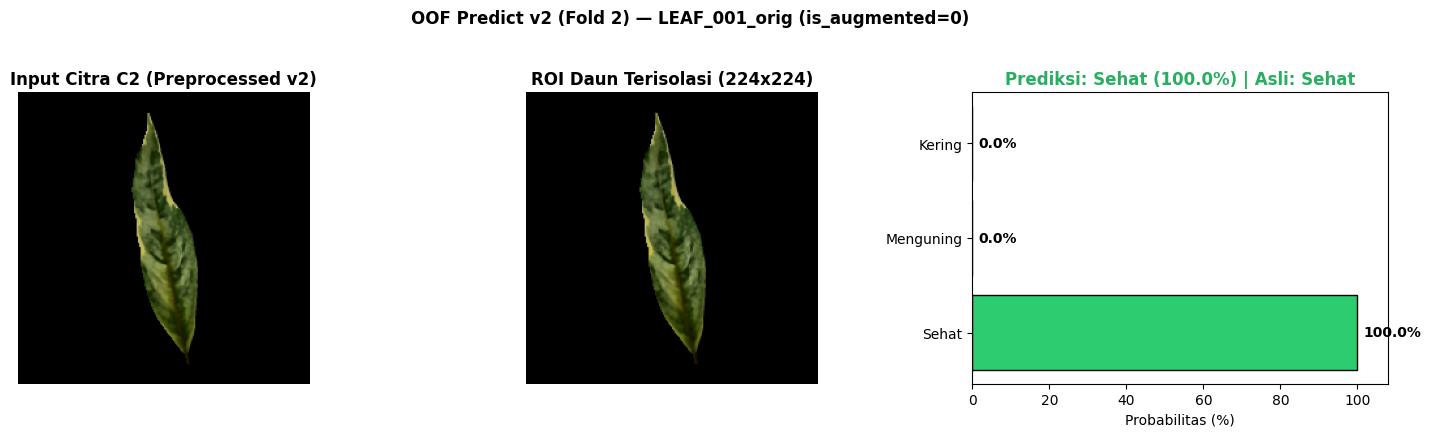

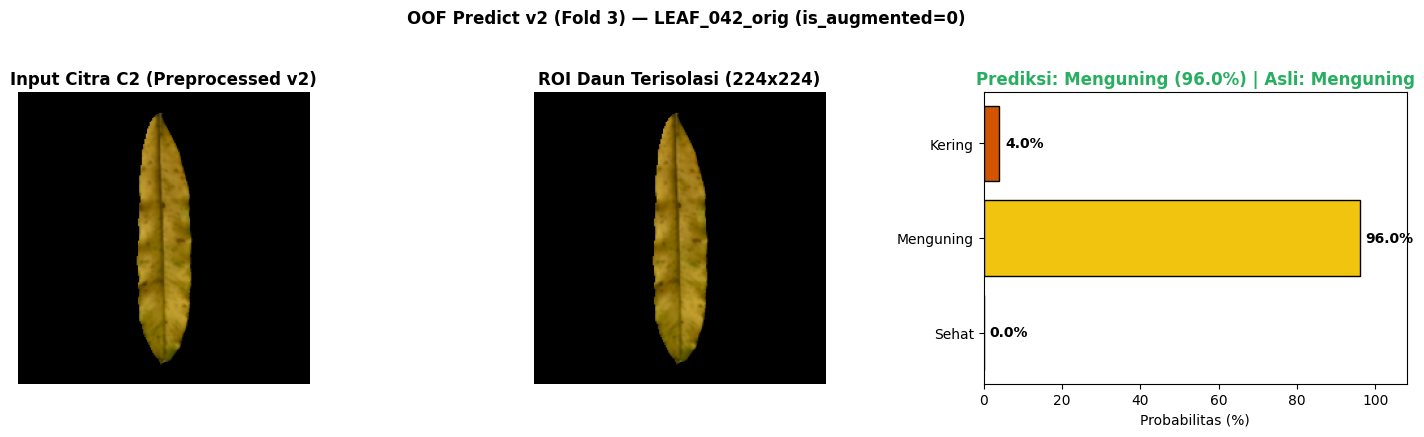

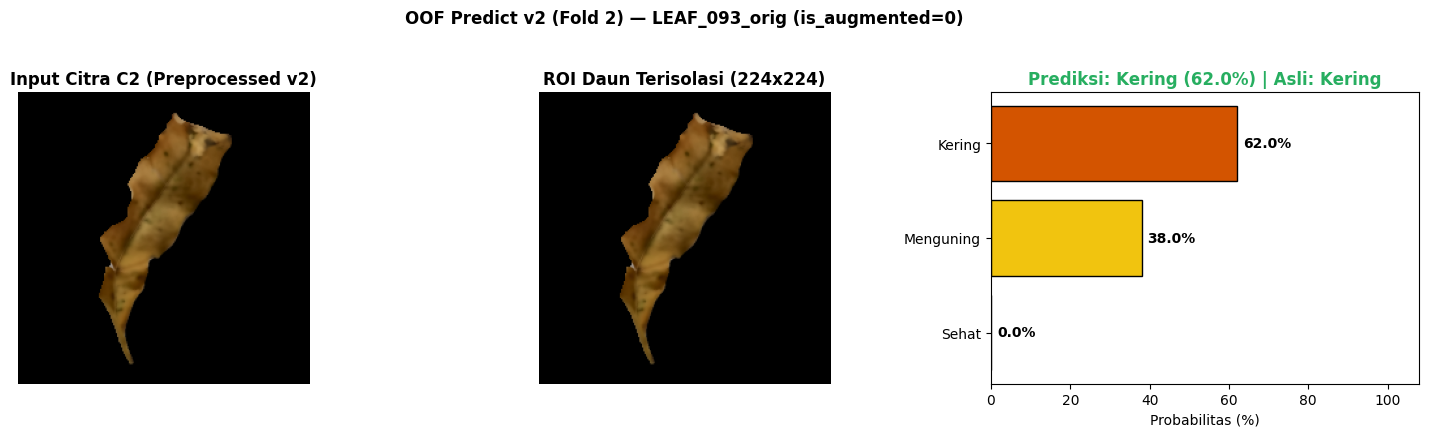

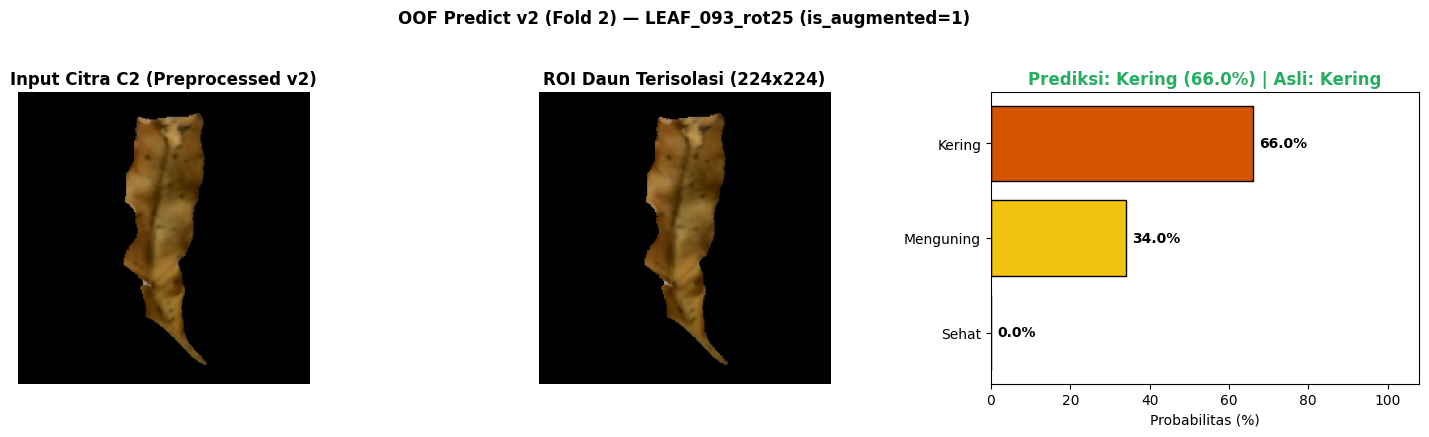

Verifikasi konsistensi fitur v2 & simulasi OOF predict bebas leakage: SUKSES.


In [9]:
# ==============================================================================
# UJI 1: SIMULASI PREDICT BEBAS LEAKAGE MENGGUNAKAN OOF FOLD MODELS (v2)
# ==============================================================================
oof_bundle = joblib.load(os.path.join(OUT_BASE, 'models', 'oof_fold_models_A.pkl'))
assert oof_bundle.get('pcd_version') == 'v2', "Bundle model bukan versi v2!"
feat_cols_loaded = oof_bundle['feature_cols']

sample_orig_rows = []
for cls_name in ['Sehat', 'Menguning', 'Kering']:
    row_cls = df_master_p2[(df_master_p2['label'] == cls_name) & (df_master_p2['is_augmented'] == 0)].iloc[0]
    sample_orig_rows.append(row_cls)

aug_row = df_master_p2[(df_master_p2['label'] == 'Kering') & (df_master_p2['is_augmented'] == 1)].iloc[0]
demo_rows = sample_orig_rows + [aug_row]

print(f"Menjalankan demo predict bebas leakage ({oof_bundle['pcd_version']}) dengan {oof_bundle['model_name']}...")
for idx_d, r in enumerate(demo_rows):
    k_fold = int(r['fold'])
    fold_est = oof_bundle['fold_models'][k_fold]
    save_demo = 'Hasil_Adita_OOF_Predict_Demo.png' if idx_d == 2 else None  # Simpan 1 sampel representatif (Kering) untuk PPT Slide 10
    res = predict_leaf_image(
        image_path=r['path_C2_masked'],
        estimator=fold_est,
        feature_cols=feat_cols_loaded,
        true_label=r['label'],
        is_preprocessed_roi=True,
        mask_path=r['path_mask'],
        title_prefix=f"OOF Predict v2 (Fold {k_fold}) — {r['sample_id']} (is_augmented={r['is_augmented']})",
        save_path=save_demo
    )
    if save_demo is not None:
        import shutil
        shutil.copyfile(save_demo, os.path.join(OUT_BASE, save_demo))

    csv_row = df_feat_A[df_feat_A['sample_id'] == r['sample_id']].iloc[0]
    vec_live = np.array([res['features'][c] for c in feat_cols_loaded], dtype=np.float64)
    vec_csv  = csv_row[feat_cols_loaded].values.astype(np.float64)
    assert np.allclose(vec_live, vec_csv, rtol=1e-5, atol=1e-6, equal_nan=True), (
        f"Fitur tidak sinkron pada {r['sample_id']}!"
    )

print("Verifikasi konsistensi fitur v2 & simulasi OOF predict bebas leakage: SUKSES.")

In [10]:
# ==============================================================================
# UJI 2: TEMPLATE PREDICT FOTO DAUN BARU EKSTERNAL (PIPELINE PCD v2)
# ==============================================================================
final_bundle = joblib.load(os.path.join(OUT_BASE, 'models', 'final_best_ml_model.pkl'))
assert final_bundle.get('pcd_version') == 'v2', "Bundle model final bukan versi v2!"

NEW_IMAGE_PATH = None  # Contoh: '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Uji_Baru/daun_tes_1.jpg'

if NEW_IMAGE_PATH is not None and os.path.exists(NEW_IMAGE_PATH):
    res_new = predict_leaf_image(
        image_path=NEW_IMAGE_PATH,
        estimator=final_bundle['pipeline'],
        feature_cols=final_bundle['feature_cols'],
        gamma_mode='auto',
        target_l=final_bundle.get('target_l', 0.716),
        is_preprocessed_roi=False,
        title_prefix=f"Prediksi Foto Eksternal Baru v2 ({final_bundle['model_name']})"
    )
    print(f"Hasil Prediksi : {res_new['pred_label']} (Confidence: {res_new['confidence']*100:.2f}%)")
    print(f"Gamma Adaptif  : {res_new['gamma_used']}")
    print(f"Probabilitas   : {res_new['probabilities']}")
else:
    print("Belum ada NEW_IMAGE_PATH yang diset / ditemukan.")
    print("Model final v2 siap digunakan di:", os.path.join(OUT_BASE, 'models', 'final_best_ml_model.pkl'))
    print("Saat sudah ada foto uji baru (misal Sesi 3 / demo live), isi variabel NEW_IMAGE_PATH lalu jalankan ulang sel ini.")

Belum ada NEW_IMAGE_PATH yang diset / ditemukan.
Model final v2 siap digunakan di: /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/models/final_best_ml_model.pkl
Saat sudah ada foto uji baru (misal Sesi 3 / demo live), isi variabel NEW_IMAGE_PATH lalu jalankan ulang sel ini.


---
## 6. Benchmark Waktu Latih, Latensi Inferensi (`ms/citra`), & Galeri Benar vs Salah (`v2`)

**Tujuan:**
1. Mengukur **waktu latih (`fit_time`)** ketiga model ML klasik pada dataset penuh $N=619$ dan skema 5-Fold CV.
2. Mengukur **latensi inferensi per citra (`ms/citra`)** secara terurai: **PCD v2** (`preprocess_raw_for_ml`), **Ekstraksi 28 Fitur** (`extract_handcrafted_features`), dan **Prediksi Classifier** (`predict` + `predict_proba`), diukur di RAM (terpisah dari I/O baca disk).
3. Menyajikan **galeri visual contoh prediksi benar vs salah** dari model OOF *tuned* terbaik pada 127 foto asli `v2`.

In [11]:
# ==============================================================================
# 6A & 6B. BENCHMARK WAKTU LATIH & LATENSI INFERENSI PER CITRA (ms/citra)
# ==============================================================================
import os
import time
import cv2
import joblib
import numpy as np
import pandas as pd
from collections import Counter
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier

OUT_BASE = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2'
RAW_DATASET_DIR = '/content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset'

if 'df_master_p2' not in globals():
    df_master_p2 = pd.read_csv(os.path.join(OUT_BASE, 'dataset_master_p2.csv'))
if 'df_feat_A' not in globals():
    df_feat_A = pd.read_csv(os.path.join(OUT_BASE, 'features_A_pcd_p2.csv'))
if 'ALL_FEATURE_COLS' not in globals():
    COLOR_COLS = ['H_mean', 'H_std', 'S_mean', 'S_std', 'V_mean', 'V_std',
                  'L_mean', 'L_std', 'a_mean', 'a_std', 'b_mean', 'b_std']
    GLCM_COLS = [f'GLCM_{p}' for p in ['contrast', 'dissimilarity', 'homogeneity', 'energy', 'correlation', 'ASM']]
    LBP_COLS = [f'LBP_bin_{i}' for i in range(10)]
    ALL_FEATURE_COLS = COLOR_COLS + GLCM_COLS + LBP_COLS

for fn_name in ['extract_handcrafted_features', 'preprocess_raw_for_ml']:
    if fn_name not in globals():
        raise RuntimeError(f"Fungsi '{fn_name}' belum didefinisikan. Jalankan Sel Bagian 1 dan Bagian 5 terlebih dahulu.")

# Siapkan konfigurasi model tuned konsensus (gunakan best_params_history jika ada di memori)
base_pipelines = {
    'SVM (RBF Kernel)': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', SVC(C=3.0, kernel='rbf', gamma=0.01, class_weight='balanced', probability=True, random_state=42))
    ]),
    'Random Forest': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', RandomForestClassifier(n_estimators=300, max_depth=6, min_samples_leaf=2, max_features='sqrt', class_weight='balanced', random_state=42))
    ]),
    'KNN': Pipeline([
        ('scaler', StandardScaler()),
        ('clf', KNeighborsClassifier(n_neighbors=7, weights='distance', metric='manhattan'))
    ])
}

import ast
_loso_csv = os.path.join(OUT_BASE, 'P2_Tabel4b_LOSO_Tuned.csv')
_saved_cons_params = {}
if os.path.exists(_loso_csv):
    _df_loso_tmp = pd.read_csv(_loso_csv)
    if {'Model ML Klasik', 'Konsensus Params'}.issubset(_df_loso_tmp.columns):
        for _, _r in _df_loso_tmp.drop_duplicates('Model ML Klasik').iterrows():
            _saved_cons_params[_r['Model ML Klasik']] = ast.literal_eval(str(_r['Konsensus Params']))

bench_models = {}
for mname, pipe in base_pipelines.items():
    p_clone = clone(pipe)
    if 'best_params_history' in globals() and mname in best_params_history and len(best_params_history[mname]) > 0:
        cons_p = {k: Counter([p[k] for p in best_params_history[mname]]).most_common(1)[0][0]
                  for k in best_params_history[mname][0]}
        p_clone.set_params(**cons_p)
    elif mname in _saved_cons_params:
        p_clone.set_params(**_saved_cons_params[mname])
    elif mname == 'Random Forest' and os.path.exists(os.path.join(OUT_BASE, 'models', 'final_best_ml_model.pkl')):
        _fb = joblib.load(os.path.join(OUT_BASE, 'models', 'final_best_ml_model.pkl'))
        if _fb.get('model_name') == 'Random Forest' and 'best_params' in _fb:
            p_clone.set_params(**_fb['best_params'])
    bench_models[mname] = p_clone

# --- 6A. Benchmark Waktu Latih (Full N=619 & 5-Fold CV) ---
X_full = df_feat_A[ALL_FEATURE_COLS].values
y_full = df_feat_A['label'].values

fit_rows = []
fitted_models = {}
N_FIT_REPEATS = 5

for mname, pipe in bench_models.items():
    # Warmup
    _m_warm = clone(pipe)
    _m_warm.fit(X_full, y_full)

    fit_times_ms = []
    for _ in range(N_FIT_REPEATS):
        m_tmp = clone(pipe)
        t0 = time.perf_counter()
        m_tmp.fit(X_full, y_full)
        fit_times_ms.append((time.perf_counter() - t0) * 1000.0)
    fitted_models[mname] = m_tmp

    # Waktu 1 siklus lengkap 5-Fold CV (fit + predict 127 citra asli)
    t_cv0 = time.perf_counter()
    for k in range(5):
        tr = df_feat_A[df_feat_A['fold'] != k]
        te = df_feat_A[(df_feat_A['fold'] == k) & (df_feat_A['is_augmented'] == 0)]
        m_cv = clone(pipe).fit(tr[ALL_FEATURE_COLS].values, tr['label'].values)
        _ = m_cv.predict(te[ALL_FEATURE_COLS].values)
    cv_time_ms = (time.perf_counter() - t_cv0) * 1000.0

    fit_rows.append({
        'Model ML Klasik': mname,
        'Waktu Latih Full N=619 (ms)': f"{np.mean(fit_times_ms):.2f} ± {np.std(fit_times_ms):.2f}",
        'Waktu Latih Full (detik)': round(np.mean(fit_times_ms) / 1000.0, 4),
        'Waktu 5-Fold CV (detik)': round(cv_time_ms / 1000.0, 4)
    })

df_bench_fit = pd.DataFrame(fit_rows)
print("=" * 88)
print("TABEL 5A (v2): BENCHMARK WAKTU LATIH MODEL ML KLASIK (N=619 & 5-FOLD CV)")
print("=" * 88)
print(df_bench_fit.to_string(index=False))

# --- 6B. Benchmark Latensi Inferensi per Citra (ms/citra) ---
df_orig_only = df_master_p2[df_master_p2['is_augmented'] == 0].copy()
sample_bench = pd.concat(
    [g.sample(n=min(10, len(g)), random_state=42) for _, g in df_orig_only.groupby('label', sort=True)],
    ignore_index=True
)

def _resolve_raw_path(row):
    folder_map = {'Sehat': 'P1_Sehat', 'Menguning': 'P1_Menguning', 'Kering': 'P1_Kering'}
    cand = os.path.join(RAW_DATASET_DIR, folder_map.get(row['label'], ''), str(row['original_filename']))
    if os.path.exists(cand):
        return cand, 'RAW kamera asli'
    for sub in ['P1_Sehat', 'P1_Menguning', 'P1_Kering']:
        cand2 = os.path.join(RAW_DATASET_DIR, sub, str(row['original_filename']))
        if os.path.exists(cand2):
            return cand2, 'RAW kamera asli'
    return row['path_A0_raw'], 'A0_raw (224x224 fallback)'

loaded_imgs = []
io_times_ms = []
input_sources = set()
for _, r in sample_bench.iterrows():
    img_p, src_kind = _resolve_raw_path(r)
    input_sources.add(src_kind)
    t_io0 = time.perf_counter()
    im = cv2.imread(img_p)
    io_times_ms.append((time.perf_counter() - t_io0) * 1000.0)
    if im is not None:
        loaded_imgs.append(im)

if len(loaded_imgs) < 3:
    raise RuntimeError("Tidak cukup citra untuk benchmark latensi.")

# Warmup 3 citra pertama agar cache OpenCV/skimage stabil
for im_w in loaded_imgs[:3]:
    _, c2_w, msk_w, _ = preprocess_raw_for_ml(im_w, gamma_mode='auto', target_l=0.716)
    f_w = extract_handcrafted_features(c2_w, mask=msk_w, use_mask=True)
    x_w = np.array([[f_w[c] for c in ALL_FEATURE_COLS]], dtype=np.float64)
    for est in fitted_models.values():
        _ = est.predict(x_w)
        _ = est.predict_proba(x_w)

pcd_times_ms, feat_times_ms = [], []
clf_times_ms = {m: [] for m in fitted_models}

for im in loaded_imgs:
    t0 = time.perf_counter()
    _, c2_224, msk_224, _ = preprocess_raw_for_ml(im, gamma_mode='auto', target_l=0.716)
    t1 = time.perf_counter()
    feats = extract_handcrafted_features(c2_224, mask=msk_224, use_mask=True)
    t2 = time.perf_counter()

    pcd_times_ms.append((t1 - t0) * 1000.0)
    feat_times_ms.append((t2 - t1) * 1000.0)
    x_in = np.array([[feats[c] for c in ALL_FEATURE_COLS]], dtype=np.float64)

    for mname, est in fitted_models.items():
        tc0 = time.perf_counter()
        _ = est.predict(x_in)
        _ = est.predict_proba(x_in)
        clf_times_ms[mname].append((time.perf_counter() - tc0) * 1000.0)

pcd_arr = np.array(pcd_times_ms)
feat_arr = np.array(feat_times_ms)

lat_rows = []
for mname in fitted_models:
    clf_arr = np.array(clf_times_ms[mname])
    tot_arr = pcd_arr + feat_arr + clf_arr
    lat_rows.append({
        'Model ML Klasik': mname,
        'N Uji': len(loaded_imgs),
        'PCD v2 (ms/citra)': f"{pcd_arr.mean():.2f} ± {pcd_arr.std():.2f}",
        '28 Fitur (ms/citra)': f"{feat_arr.mean():.2f} ± {feat_arr.std():.2f}",
        'Predict + Proba (ms/citra)': f"{clf_arr.mean():.3f} ± {clf_arr.std():.3f}",
        'Total End-to-End (ms/citra)': f"{tot_arr.mean():.2f} ± {tot_arr.std():.2f}",
        'Throughput (FPS)': round(1000.0 / tot_arr.mean(), 2)
    })

df_bench_lat = pd.DataFrame(lat_rows)
print("\n" + "=" * 108)
print(f"TABEL 5B (v2): BENCHMARK LATENSI INFERENSI PER CITRA (Sumber: {', '.join(sorted(input_sources))} | Mean I/O imread: {np.mean(io_times_ms):.2f} ms)")
print("=" * 108)
print(df_bench_lat.to_string(index=False))

df_bench_fit.to_csv(os.path.join(OUT_BASE, 'P2_Tabel5_Benchmark_Waktu_Latih.csv'), index=False)
df_bench_lat.to_csv(os.path.join(OUT_BASE, 'P2_Tabel5b_Benchmark_Latensi_Inferensi.csv'), index=False)
print("\nTersimpan di:", os.path.join(OUT_BASE, 'P2_Tabel5_Benchmark_Waktu_Latih.csv'))
print("Tersimpan di:", os.path.join(OUT_BASE, 'P2_Tabel5b_Benchmark_Latensi_Inferensi.csv'))


TABEL 5A (v2): BENCHMARK WAKTU LATIH MODEL ML KLASIK (N=619 & 5-FOLD CV)
 Model ML Klasik Waktu Latih Full N=619 (ms)  Waktu Latih Full (detik)  Waktu 5-Fold CV (detik)
SVM (RBF Kernel)                35.02 ± 0.35                    0.0350                   0.1601
   Random Forest              932.26 ± 12.69                    0.9323                   5.2713
             KNN                 2.96 ± 0.07                    0.0030                   0.0445

TABEL 5B (v2): BENCHMARK LATENSI INFERENSI PER CITRA (Sumber: RAW kamera asli | Mean I/O imread: 1554.60 ms)
 Model ML Klasik  N Uji PCD v2 (ms/citra) 28 Fitur (ms/citra) Predict + Proba (ms/citra) Total End-to-End (ms/citra)  Throughput (FPS)
SVM (RBF Kernel)     30    211.74 ± 63.05       82.45 ± 14.81              1.752 ± 0.316              295.94 ± 76.47              3.38
   Random Forest     30    211.74 ± 63.05       82.45 ± 14.81            47.791 ± 12.693              341.98 ± 87.61              2.92
             KNN     30    2

Model OOF Tuned: Random Forest | Total Benar: 118/127 | Total Salah: 9/127


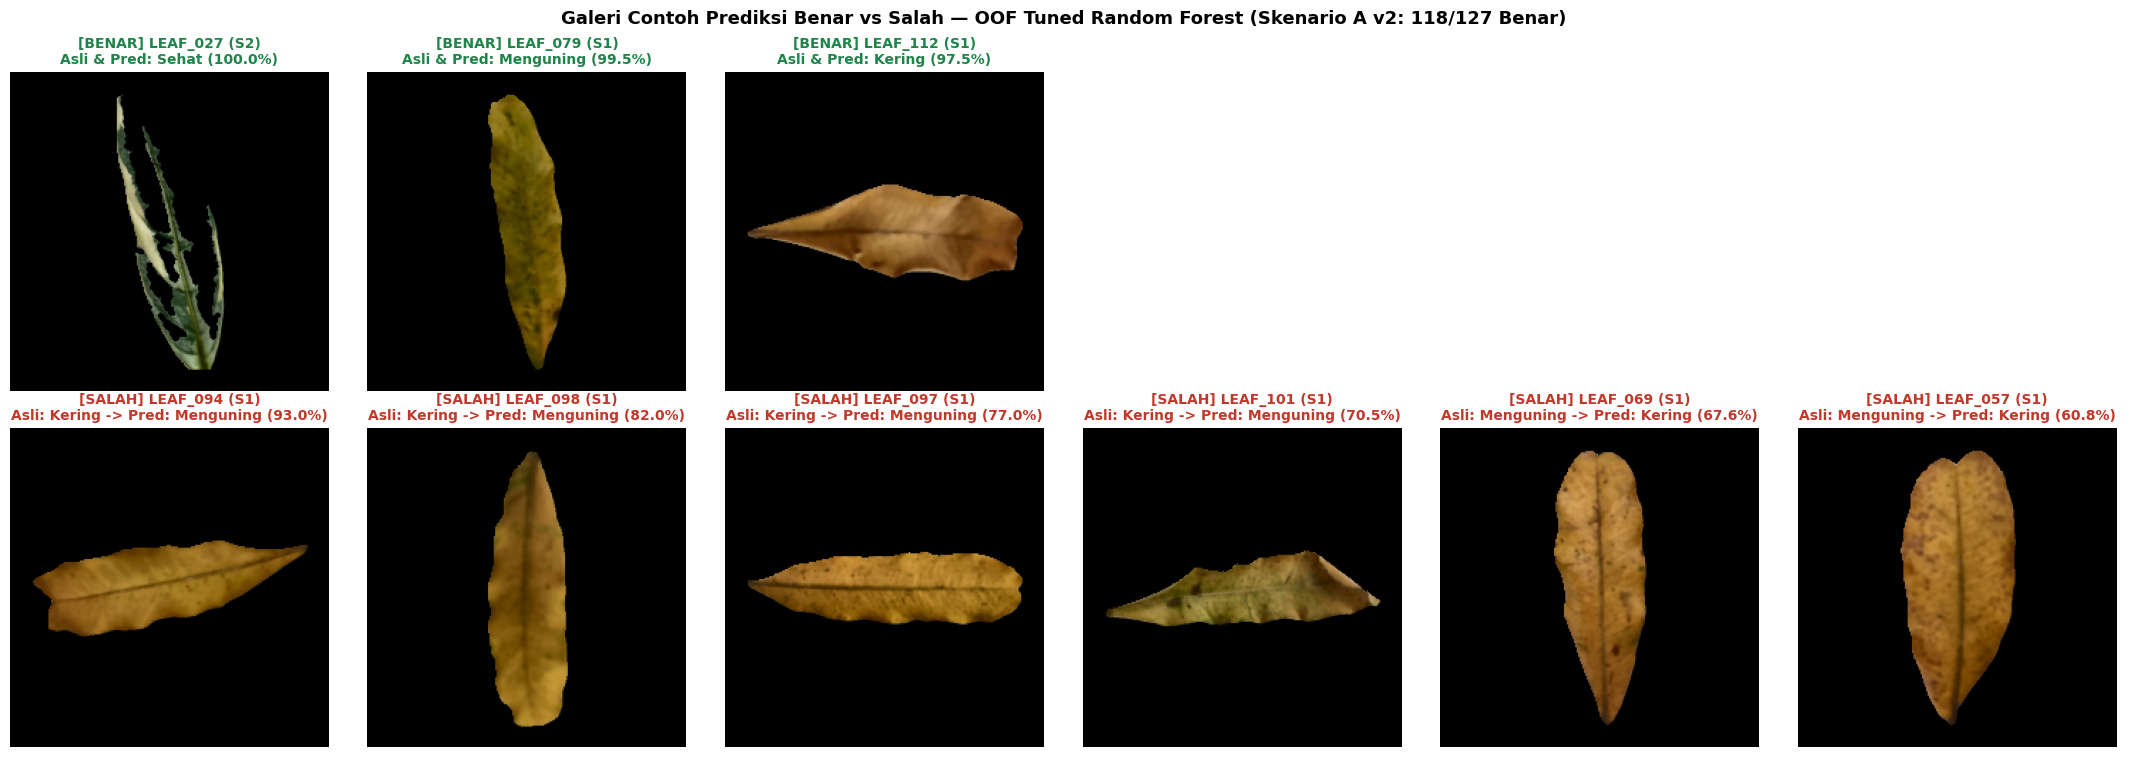

Galeri tersimpan di: /content/drive/MyDrive/Project Akhir Computer Vision/Developments/Dataset_P2_Processed_v2/P2_Slide13b_Galeri_Benar_vs_Salah_Tuned.png


In [12]:
# ==============================================================================
# 6C. GALERI VISUALISASI CONTOH PREDIKSI BENAR VS SALAH (OOF TUNED ML KLASIK v2)
# ==============================================================================
import shutil
import matplotlib.pyplot as plt

oof_csv_tuned = os.path.join(OUT_BASE, 'oof_ml_A_tuned_p2.csv')
oof_bundle_path = os.path.join(OUT_BASE, 'models', 'oof_fold_models_A.pkl')

if not os.path.exists(oof_csv_tuned) or not os.path.exists(oof_bundle_path):
    raise FileNotFoundError("Pastikan Sel Bagian 4 (oof_ml_A_tuned_p2.csv) & Bagian 5 (oof_fold_models_A.pkl) sudah dijalankan.")

oof_bundle_g = joblib.load(oof_bundle_path)
target_model = oof_bundle_g['model_name']
df_oof_all = pd.read_csv(oof_csv_tuned)
df_oof_m = df_oof_all[df_oof_all['model'] == target_model].merge(
    df_master_p2[['sample_id', 'parent_id', 'original_filename', 'sesi', 'fold', 'path_C2_masked']],
    on=['sample_id', 'fold'], how='left'
)

# Hitung confidence OOF bebas leakage untuk tiap sampel
confs = []
feat_indexed = df_feat_A.set_index('sample_id')
feat_cols_g = oof_bundle_g['feature_cols']
for _, r in df_oof_m.iterrows():
    est_k = oof_bundle_g['fold_models'][int(r['fold'])]
    x_row = feat_indexed.loc[r['sample_id'], feat_cols_g].values.astype(np.float64).reshape(1, -1)
    confs.append(float(np.max(est_k.predict_proba(x_row)[0])) * 100.0)
df_oof_m['conf_pct'] = confs

df_ok = df_oof_m[df_oof_m['y_true'] == df_oof_m['y_pred']].copy()
df_err = df_oof_m[df_oof_m['y_true'] != df_oof_m['y_pred']].copy()

# Ambil 3 contoh BENAR representatif (1 per kelas dengan confidence tertinggi) & hingga 6 contoh SALAH
ok_samples = []
for cls_name in ['Sehat', 'Menguning', 'Kering']:
    sub_c = df_ok[df_ok['y_true'] == cls_name].sort_values('conf_pct', ascending=False)
    if len(sub_c) > 0:
        ok_samples.append(sub_c.iloc[0])
df_ok_show = pd.DataFrame(ok_samples)
df_err_show = df_err.sort_values('conf_pct', ascending=False).head(min(6, len(df_err)))

print(f"Model OOF Tuned: {target_model} | Total Benar: {len(df_ok)}/127 | Total Salah: {len(df_err)}/127")

n_cols = max(len(df_ok_show), len(df_err_show), 1)
fig, axes = plt.subplots(2, n_cols, figsize=(3.6 * n_cols, 7.6))
if n_cols == 1:
    axes = np.array(axes).reshape(2, 1)

for r_idx in range(2):
    for c_idx in range(n_cols):
        axes[r_idx, c_idx].axis('off')

for c_idx, (_, row_ok) in enumerate(df_ok_show.iterrows()):
    img_ok = cv2.imread(row_ok['path_C2_masked'])
    axes[0, c_idx].imshow(cv2.cvtColor(img_ok, cv2.COLOR_BGR2RGB))
    axes[0, c_idx].set_title(
        f"[BENAR] {row_ok['parent_id']} (S{row_ok['sesi']})\n"
        f"Asli & Pred: {row_ok['y_pred']} ({row_ok['conf_pct']:.1f}%)",
        fontsize=10, fontweight='bold', color='#1e8449'
    )

for c_idx, (_, row_er) in enumerate(df_err_show.iterrows()):
    img_er = cv2.imread(row_er['path_C2_masked'])
    axes[1, c_idx].imshow(cv2.cvtColor(img_er, cv2.COLOR_BGR2RGB))
    axes[1, c_idx].set_title(
        f"[SALAH] {row_er['parent_id']} (S{row_er['sesi']})\n"
        f"Asli: {row_er['y_true']} -> Pred: {row_er['y_pred']} ({row_er['conf_pct']:.1f}%)",
        fontsize=10, fontweight='bold', color='#c0392b'
    )

plt.suptitle(
    f"Galeri Contoh Prediksi Benar vs Salah — OOF Tuned {target_model} (Skenario A v2: {len(df_ok)}/127 Benar)",
    fontsize=13, fontweight='bold', y=0.99
)
plt.tight_layout()
gal_name = 'P2_Slide13b_Galeri_Benar_vs_Salah_Tuned.png'
plt.savefig(gal_name, dpi=300, bbox_inches='tight')
shutil.copyfile(gal_name, os.path.join(OUT_BASE, gal_name))
plt.show()
print("Galeri tersimpan di:", os.path.join(OUT_BASE, gal_name))
